# Affinity Predictor Evaluation

## Imports

In [1]:
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader, Dataset

from models.predictor_model import AffinityPredictor, predict
from helpers import create_model_name

sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath(os.path.join("..", "task2")))
from utils.evaluation import concordance_index, hit_at_k, mean_squared_error

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", DEVICE)

Using: cuda


## Config

In [2]:
PROJECT_ROOT = os.path.abspath("..")

DATA_DIR = os.path.join(PROJECT_ROOT, "open_task", "data")
DRUG_EMBEDDING_FILE = os.path.join(DATA_DIR, "drug_embedding.npy")
PROTEIN_EMBEDDING_FILE = os.path.join(DATA_DIR, "protein_embedding.npy")
DRUG_MAPPING_FILE = os.path.join(DATA_DIR, "drug_mapping.csv")
PROTEIN_MAPPING_FILE = os.path.join(DATA_DIR, "protein_mapping.csv")
SPLIT_PATTERN = os.path.join(DATA_DIR, "protein-holdout-{holdout}", "{dataset}_{split}.csv")
DRUG_ID_COLUMN = "drug_id"
PROTEIN_ID_COLUMN = "protein_id"
SMILES_COLUMN = "compound_iso_smiles"
SEQUENCE_COLUMN = "target_sequence"
AFFINITY_COLUMN = "affinity"
PREDICTION_COLUMN = "prediction"
FALLBACK_COLUMN = "fallback"
COLD_COLUMN = "cold"
SPLITS = ("val", "test")
TRAIN_SPLIT = "train"

DATASETS = ["kiba", "davis"]

HOLDOUTS = [0.0, 0.1, 0.2, 0.3, 0.5, 0.75]

BIASED_MF_PATTERN = os.path.join(
    PROJECT_ROOT, "task2", "saved_models", "{dataset}_biased_mf.npz")
BIASED_MF_SPLIT = "val"
BIASED_MF_HOLDOUT = 0.0

BATCH_SIZE = 1024
HIT_K = (1, 5)

MODEL_PATTERN = os.path.join(
    PROJECT_ROOT, "open_task", "models", "saved_models", "predictor_{name}.pt")
PREDICTION_PATTERN = os.path.join(
    PROJECT_ROOT, "open_task", "predictions", "{model}_{name}_{split}.csv")

FIGURE_DIR = os.path.join(PROJECT_ROOT, "open_task", "figures")
CURVE_PATTERN = os.path.join(FIGURE_DIR, "curves_{split}_{group}.png")
PANEL_PATTERN = os.path.join(FIGURE_DIR, "curve_{split}_{group}_{dataset}_{metric}.png")
FOCUS_PATTERN = os.path.join(FIGURE_DIR, "focus_{name}_{split}_{group}.png")

os.makedirs(FIGURE_DIR, exist_ok=True)

PREDICTOR_COLOR = "#2a78d6"
DRUG_CF_COLOR = "#e34948"
PROTEIN_CF_COLOR = "#1baf7a"
BIASED_MF_COLOR = "#eda100"
IMPROVED_MF_COLOR = "#8250c4"
TEXT_COLOR = "#0b0b0b"
MUTED_COLOR = "#52514e"
GRID_COLOR = "#e5e4e0"

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

## Embeddings

In [3]:
drug_vectors = torch.from_numpy(np.load(DRUG_EMBEDDING_FILE)).to(DEVICE)
protein_vectors = torch.from_numpy(np.load(PROTEIN_EMBEDDING_FILE)).to(DEVICE)

display(pd.DataFrame(
    [
        {"entity": "drug", "rows": drug_vectors.shape[0], "dim": drug_vectors.shape[1]},
        {"entity": "protein", "rows": protein_vectors.shape[0], "dim": protein_vectors.shape[1]},
    ]
).set_index("entity"))

,rows,dim
entity,,
drug,2127,768
protein,429,320


## Splits

In [4]:
class PairDataset(Dataset):
    def __init__(self, frame):
        self.drug_ids = torch.tensor(frame[DRUG_ID_COLUMN].to_numpy(), dtype=torch.long)
        self.protein_ids = torch.tensor(frame[PROTEIN_ID_COLUMN].to_numpy(), dtype=torch.long)
        self.affinities = torch.tensor(frame[AFFINITY_COLUMN].to_numpy(), dtype=torch.float32)

    def __len__(self):
        return len(self.affinities)

    def __getitem__(self, index):
        return self.drug_ids[index], self.protein_ids[index], self.affinities[index]

drug_mapping = pd.read_csv(DRUG_MAPPING_FILE, keep_default_na=False)
protein_mapping = pd.read_csv(PROTEIN_MAPPING_FILE, keep_default_na=False)
smiles = dict(zip(drug_mapping[DRUG_ID_COLUMN], drug_mapping[SMILES_COLUMN]))
sequences = dict(zip(protein_mapping[PROTEIN_ID_COLUMN], protein_mapping[SEQUENCE_COLUMN]))

def read_split(dataset, holdout, split):
    """One holdout split, with the text columns Hit@K ranks on."""
    frame = pd.read_csv(SPLIT_PATTERN.format(dataset=dataset, holdout=holdout, split=split))
    frame[SMILES_COLUMN] = frame[DRUG_ID_COLUMN].map(smiles)
    frame[SEQUENCE_COLUMN] = frame[PROTEIN_ID_COLUMN].map(sequences)
    return frame

frames = {}
for dataset in DATASETS:
    for holdout in HOLDOUTS:
        trained = set(read_split(dataset, holdout, TRAIN_SPLIT)[PROTEIN_ID_COLUMN])
        for split in SPLITS:
            frame = read_split(dataset, holdout, split)
            frame[COLD_COLUMN] = ~frame[PROTEIN_ID_COLUMN].isin(trained)
            frames[dataset, holdout, split] = frame

loaders = {
    key: DataLoader(PairDataset(frame), batch_size=BATCH_SIZE)
    for key, frame in frames.items()
}

display(pd.DataFrame(
    [
        {
            "dataset": dataset,
            "holdout": holdout,
            "split": split,
            "pairs": len(frame),
            "cold rows": int(frame[COLD_COLUMN].sum()),
        }
        for (dataset, holdout, split), frame in frames.items()
    ]
).set_index(["dataset", "holdout", "split"]))

pairs  cold rows
dataset holdout split                  
kiba    0.0000  val    17648          0
                test   17650          0
        0.1000  val    17648       1766
                test   17650       1849
        0.2000  val    17648       3711
                test   17650       3854
        0.3000  val    17648       5196
                test   17650       5359
        0.5000  val    17648       8346
                test   17650       8412
        0.7500  val    17648      12887
                test   17650      12979
davis   0.0000  val     3865          0
                test    3867          0
        0.1000  val     3865        380
                test    3867        389
        0.2000  val     3865        766
                test    3867        796
        0.3000  val     3865       1139
                test    3867       1213
        0.5000  val     3865       1933
                test    3867       1968
        0.7500  val     3865       2870
                test    3867       2913

## Model

In [5]:
models = {}
loaded = []

for dataset in DATASETS:
    for holdout in HOLDOUTS:
        model_file = MODEL_PATTERN.format(name=create_model_name(dataset, holdout))
        state = torch.load(model_file, map_location=DEVICE)

        weights = [key for key in state if key.startswith("mlp.") and key.endswith("weight")]
        hidden_sizes = [state[key].shape[0] for key in weights[:-1]]

        model = AffinityPredictor(drug_vectors, protein_vectors, hidden_sizes, dropout=0.0).to(DEVICE)
        model.load_state_dict(state)
        model.eval()
        models[dataset, holdout] = model

        loaded.append({
            "dataset": dataset,
            "holdout": holdout,
            "checkpoint": os.path.basename(model_file),
            "hidden sizes": str(tuple(hidden_sizes)),
        })

display(pd.DataFrame(loaded).set_index(["dataset", "holdout"]))

checkpoint     hidden sizes
dataset holdout                                                  
kiba    0.0000     predictor_kiba_holdout_0.0.pt  (512, 256, 256)
        0.1000     predictor_kiba_holdout_0.1.pt  (512, 256, 256)
        0.2000     predictor_kiba_holdout_0.2.pt  (512, 256, 256)
        0.3000     predictor_kiba_holdout_0.3.pt  (512, 256, 256)
        0.5000     predictor_kiba_holdout_0.5.pt  (512, 256, 256)
        0.7500    predictor_kiba_holdout_0.75.pt  (512, 256, 256)
davis   0.0000    predictor_davis_holdout_0.0.pt  (512, 256, 256)
        0.1000    predictor_davis_holdout_0.1.pt  (512, 256, 256)
        0.2000    predictor_davis_holdout_0.2.pt  (512, 256, 256)
        0.3000    predictor_davis_holdout_0.3.pt  (512, 256, 256)
        0.5000    predictor_davis_holdout_0.5.pt  (512, 256, 256)
        0.7500   predictor_davis_holdout_0.75.pt  (512, 256, 256)

## Predictions

In [6]:
MODEL_NAME = "AffinityPredictor"
BIASED_MF_NAME = "biased MF (task 2)"
LABELS = {
    "global_mean": "global mean",
    "drug_cf": "drug CF",
    "protein_cf": "protein CF",
    "biased_mf": "biased MF",
    "improved_biased_mf": "improved biased MF",
}

def read_saved(model, dataset, holdout, split, frame):
    """Predictions written by another notebook, aligned to this frame by pair keys."""
    path = PREDICTION_PATTERN.format(
        model=model, name=create_model_name(dataset, holdout), split=split)
    saved = pd.read_csv(path)
    return frame[[DRUG_ID_COLUMN, PROTEIN_ID_COLUMN]].merge(
        saved, on=[DRUG_ID_COLUMN, PROTEIN_ID_COLUMN], how="left")

predictions = {}
fallbacks = []

for (dataset, holdout, split), frame in frames.items():
    predicted, _ = predict(models[dataset, holdout], loaders[dataset, holdout, split], DEVICE)

    row = {MODEL_NAME: predicted}

    for baseline, label in LABELS.items():
        saved = read_saved(baseline, dataset, holdout, split, frame)
        row[label] = saved[PREDICTION_COLUMN].to_numpy()

        if baseline != "global_mean":
            fallback = saved[FALLBACK_COLUMN].to_numpy()
            row[f"{label} + predictor"] = np.where(fallback, predicted, row[label])
            fallbacks.append({
                "dataset": dataset,
                "holdout": holdout,
                "split": split,
                "model": label,
                "cold rows": int(frame[COLD_COLUMN].sum()),
                "fallback rows": int(fallback.sum()),
            })

    predictions[dataset, holdout, split] = row

display(pd.DataFrame(fallbacks).set_index(["dataset", "holdout", "split", "model"]))

cold rows  fallback rows
dataset holdout split model                                       
kiba    0.0000  val   drug CF                     0            449
                      protein CF                  0              1
                      biased MF                   0              0
                      improved biased MF          0              0
                test  drug CF                     0            396
                      protein CF                  0              0
                      biased MF                   0              0
                      improved biased MF          0              0
        0.1000  val   drug CF                  1766           2164
                      protein CF               1766           1767
                      biased MF                1766           1766
                      improved biased MF       1766              0
                test  drug CF                  1849           2196
                      protein CF               1849           1849
                      biased MF                1849           1849
                      improved biased MF       1849              0
        0.2000  val   drug CF                  3711           4081
                      protein CF               3711           3713
                      biased MF                3711           3711
                      improved biased MF       3711              0
                test  drug CF                  3854           4178
                      protein CF               3854           3854
                      biased MF                3854           3854
                      improved biased MF       3854              0
        0.3000  val   drug CF                  5196           5578
                      protein CF               5196           5198
                      biased MF                5196           5196
                      improved biased MF       5196              0
                test  drug CF                  5359           5694
                      protein CF               5359           5359
                      biased MF                5359           5359
                      improved biased MF       5359              0
        0.5000  val   drug CF                  8346           8706
                      protein CF               8346           8367
                      biased MF                8346           8346
                      improved biased MF       8346              0
                test  drug CF                  8412           8753
                      protein CF               8412           8423
                      biased MF                8412           8412
                      improved biased MF       8412              0
        0.7500  val   drug CF                 12887          13305
                      protein CF              12887          12924
                      biased MF               12887          12911
                      improved biased MF      12887            113
                test  drug CF                 12979          13411
                      protein CF              12979          13009
                      biased MF               12979          12995
                      improved biased MF      12979            113
davis   0.0000  val   drug CF                     0              0
                      protein CF                  0              0
                      biased MF                   0              0
                      improved biased MF          0              0
                test  drug CF                     0              0
                      protein CF                  0              0
                      biased MF                   0              0
                      improved biased MF          0              0
        0.1000  val   drug CF                   380            380
                      protein CF                380            380
                      

## Metrics

In [7]:
def error_metrics(frame, predicted):
    """Per-row scores, unaffected by which other rows are present."""
    mse = mean_squared_error(frame[AFFINITY_COLUMN], predicted)
    return {
        "MSE": mse,
        "RMSE": mse ** 0.5,
        "CI": concordance_index(frame[AFFINITY_COLUMN], predicted),
    }

def within_drug_ci(frame, predicted):
    """Concordance inside one ligand's own candidate list, averaged over ligands.

    The cold-target question in a single number. concordance_index pools every pair in the
    rows given, so a model predicting one constant per drug still scores well above 0.5 by
    ordering drugs against each other. Inside one drug that constant orders nothing and
    scores exactly 0.5, which is where drug CF, protein CF and biased MF all sit on cold
    rows. concordance_index returns NaN for a ligand whose candidates all tie on the actual
    affinity, and those carry no information, so they drop out.
    """
    scores = [
        concordance_index(frame[AFFINITY_COLUMN].to_numpy()[rows], predicted[rows])
        for rows in frame.groupby(SMILES_COLUMN).indices.values()
        if len(rows) > 1
    ]
    scores = [score for score in scores if np.isfinite(score)]
    return float(np.mean(scores)) if scores else float("nan")

def query_eligibility(frame, query_column):
    """Per K, the queries Hit@K can actually test.

    A query with at most K candidates has all of them in its own top K, so it hits for
    any model at all and measures nothing. This is Task 2's restricted Hit@5 rule, kept
    as is so the numbers compare; queries whose candidates all tie on actual score stay
    in and hit for every model.
    """
    counts = frame.groupby(query_column)[AFFINITY_COLUMN].transform("size").to_numpy()
    return {k: counts > k for k in HIT_K}

def ranking_metrics(frame, predicted, query_column=SMILES_COLUMN,
                    candidate_column=SEQUENCE_COLUMN):
    """Hit@K over the rows given, so slicing to cold rows asks about new targets only.

    Task 2.3 asks whether a model can tell a ligand's unseen targets apart, so the best
    of those unseen targets is the intended answer. Ineligible queries drop out whole,
    which leaves every surviving query its own candidates and its own best.
    """
    eligible = query_eligibility(frame, query_column)
    return {
        f"Hit@{k}": hit_at_k(
            frame[selected],
            predicted[selected],
            k=k,
            drug_col=query_column,
            target_col=candidate_column,
            score_col=AFFINITY_COLUMN,
        )["hit_rate"]
        for k, selected in eligible.items()
    }

def reference_metrics(frame, predicted):
    """Task 2.2 as published: every ligand counted, no eligibility filter."""
    row = error_metrics(frame, predicted)

    for k in HIT_K:
        row[f"Hit@{k}"] = hit_at_k(
            frame,
            predicted,
            k=k,
            drug_col=SMILES_COLUMN,
            target_col=SEQUENCE_COLUMN,
            score_col=AFFINITY_COLUMN,
        )["hit_rate"]

    return row

def biased_mf_metrics(dataset):
    saved = np.load(BIASED_MF_PATTERN.format(dataset=dataset), allow_pickle=True)
    mse = float(saved["metric_val_mse"])
    row = {"MSE": mse, "RMSE": mse ** 0.5, "CI": float(saved["metric_val_ci"])}

    for k in HIT_K:
        row[f"Hit@{k}"] = float(saved[f"metric_val_hit_at_{k}"])

    return row

## Query coverage

In [8]:
coverage = []

for (dataset, holdout, split), frame in frames.items():
    cold = frame[COLD_COLUMN].to_numpy()

    for group, selected in (
        ("all rows", np.ones(len(frame), dtype=bool)),
        ("warm rows", ~cold),
        ("cold rows", cold),
    ):
        subset = frame[selected]
        if not len(subset):
            continue

        coverage.append({
            "dataset": dataset,
            "holdout": holdout,
            "split": split,
            "group": group,
            "ligands": subset[SMILES_COLUMN].nunique(),
            "median targets": subset.groupby(SMILES_COLUMN)[SEQUENCE_COLUMN].size().median(),
            **{
                f"testable@{k}": subset[eligible][SMILES_COLUMN].nunique()
                for k, eligible in query_eligibility(subset, SMILES_COLUMN).items()
            },
        })

display(pd.DataFrame(coverage).set_index(["dataset", "holdout", "split", "group"]))

ligands  median targets  testable@1  \
dataset holdout split group                                            
kiba    0.0000  val   all rows      1967          6.0000        1719   
                      warm rows     1967          6.0000        1719   
                test  all rows      1951          6.0000        1707   
                      warm rows     1951          6.0000        1707   
        0.1000  val   all rows      1967          6.0000        1719   
                      warm rows     1932          5.0000        1651   
                      cold rows     1034          1.0000         456   
                test  all rows      1951          6.0000        1707   
                      warm rows     1917          5.0000        1625   
                      cold rows     1055          1.0000         499   
        0.2000  val   all rows      1967          6.0000        1719   
                      warm rows     1899          5.0000        1588   
                      cold rows     1396          2.0000         898   
                test  all rows      1951          6.0000        1707   
                      warm rows     1891          5.0000        1541   
                      cold rows     1388          2.0000         930   
        0.3000  val   all rows      1967          6.0000        1719   
                      warm rows     1878          4.0000        1539   
                      cold rows     1519          3.0000        1071   
                test  all rows      1951          6.0000        1707   
                      warm rows     1869          4.0000        1508   
                      cold rows     1503          3.0000        1062   
        0.5000  val   all rows      1967          6.0000        1719   
                      warm rows     1774          4.0000        1370   
                      cold rows     1697          4.0000        1322   
                test  all rows      1951          6.0000        1707   
                      warm rows     1779          4.0000        1362   
                      cold rows     1688          4.0000        1271   
        0.7500  val   all rows      1967          6.0000        1719   
                      warm rows     1437          2.0000         972   
                      cold rows     1863          5.0000        1544   
                test  all rows      1951          6.0000        1707   
                      warm rows     1462          2.0000         957   
                      cold rows     1854          5.0000        1528   
davis   0.0000  val   all rows        68         57.5000          68   
                      warm rows       68         57.5000          68   
                test  all rows        68         57.0000          68   
                      warm rows       68         57.0000          68   
        0.1000  val   all rows        68         57.5000          68   
                      warm rows       68         51.0000          68   
                      cold rows       68          5.0000          68   
                test  all rows        68         57.0000          68   
                      warm rows       68         51.0000          68   
                      cold rows       68          6.0000          68   
        0.2000  val   all rows        68         57.5000          68   
                      warm rows       68         46.0000          68   
                      cold rows       68         11.0000          68   
                test  all rows        68         57.0000          68   
                      warm rows       68         45.0000          68   
                      cold rows       68         12.0000          68   
        0.3000  val   all rows        68         57.5000          68   
                      warm rows       68         40.5000          68   
                      cold rows       68         17.0000          68   
                test  all rows        68         57.0000          68   
 

## Task 2 reproduction

In [9]:
for dataset in DATASETS:
    frame = frames[dataset, BIASED_MF_HOLDOUT, BIASED_MF_SPLIT]
    rows = [
        {"model": name, **reference_metrics(frame, predicted)}
        for name, predicted in predictions[dataset, BIASED_MF_HOLDOUT, BIASED_MF_SPLIT].items()
    ]
    rows.append({"model": BIASED_MF_NAME, **biased_mf_metrics(dataset)})

    print(f"{dataset} / {BIASED_MF_SPLIT} / holdout {BIASED_MF_HOLDOUT} / ligand as query")
    display(pd.DataFrame(rows).set_index("model"))

kiba / val / holdout 0.0 / ligand as query


,MSE,RMSE,CI,Hit@1,Hit@5
model,,,,,
AffinityPredictor,0.2822,0.5312,0.7955,0.5862,0.8907
global mean,0.6878,0.8293,0.5000,0.3757,0.7178
drug CF,0.2090,0.4572,0.8489,0.6660,0.9349
drug CF + predictor,0.2095,0.4577,0.8480,0.6736,0.9365
protein CF,0.2398,0.4897,0.8265,0.6202,0.9217
protein CF + predictor,0.2396,0.4895,0.8266,0.6202,0.9217
biased MF,0.1888,0.4345,0.8481,0.6904,0.9522
biased MF + predictor,0.1888,0.4345,0.8481,0.6904,0.9522
improved biased MF,0.1888,0.4345,0.8481,0.6904,0.9522


davis / val / holdout 0.0 / ligand as query


,MSE,RMSE,CI,Hit@1,Hit@5
model,,,,,
AffinityPredictor,0.3476,0.5896,0.8405,0.2500,0.5147
global mean,0.6751,0.8217,0.5000,0.1029,0.1324
drug CF,0.3230,0.5683,0.8561,0.3088,0.6765
drug CF + predictor,0.3230,0.5683,0.8561,0.3088,0.6765
protein CF,0.2827,0.5317,0.8661,0.3235,0.6471
protein CF + predictor,0.2827,0.5317,0.8661,0.3235,0.6471
biased MF,0.2598,0.5097,0.8732,0.3382,0.7206
biased MF + predictor,0.2598,0.5097,0.8732,0.3382,0.7206
improved biased MF,0.2598,0.5097,0.8732,0.3382,0.7206


## Comparison

In [10]:
GROUPS = ("all rows", "warm rows", "cold rows")

measurements = []

for dataset in DATASETS:
    for split in SPLITS:
        for group in GROUPS:
            rows = []

            for holdout in HOLDOUTS:
                frame = frames[dataset, holdout, split]
                cold = frame[COLD_COLUMN].to_numpy()

                if group == "cold rows" and not cold.any():
                    continue
                selected = {
                    "all rows": np.ones(len(frame), dtype=bool),
                    "warm rows": ~cold,
                    "cold rows": cold,
                }[group]
                subset = frame[selected]

                rows += [
                    {
                        "holdout": holdout,
                        "model": name,
                        **error_metrics(subset, predicted[selected]),
                        "CI (in drug)": within_drug_ci(subset, predicted[selected]),
                        **ranking_metrics(subset, predicted[selected]),
                    }
                    for name, predicted in predictions[dataset, holdout, split].items()
                ]

            measurements += [
                {"dataset": dataset, "split": split, "group": group, **row} for row in rows
            ]

            print(f"{dataset} / {split} / {group}")
            display(pd.DataFrame(rows).set_index(["holdout", "model"]))

kiba / val / all rows


MSE   RMSE     CI  CI (in drug)  \
holdout model                                                               
0.0000  AffinityPredictor              0.2822 0.5312 0.7955        0.7103   
        global mean                    0.6878 0.8293 0.5000        0.5000   
        drug CF                        0.2090 0.4572 0.8489        0.7894   
        drug CF + predictor            0.2095 0.4577 0.8480        0.7955   
        protein CF                     0.2398 0.4897 0.8265        0.7367   
        protein CF + predictor         0.2396 0.4895 0.8266        0.7367   
        biased MF                      0.1888 0.4345 0.8481        0.7810   
        biased MF + predictor          0.1888 0.4345 0.8481        0.7810   
        improved biased MF             0.1888 0.4345 0.8481        0.7810   
        improved biased MF + predictor 0.1888 0.4345 0.8481        0.7810   
0.1000  AffinityPredictor              0.2557 0.5056 0.8041        0.7185   
        global mean                    0.6879 0.8294 0.5000        0.5000   
        drug CF                        0.2295 0.4790 0.8382        0.7691   
        drug CF + predictor            0.2259 0.4753 0.8361        0.7707   
        protein CF                     0.2969 0.5449 0.8006        0.7139   
        protein CF + predictor         0.2565 0.5065 0.8163        0.7254   
        biased MF                      0.2148 0.4634 0.8363        0.7660   
        biased MF + predictor          0.2111 0.4595 0.8348        0.7646   
        improved biased MF             0.2092 0.4574 0.8386        0.7666   
        improved biased MF + predictor 0.2092 0.4574 0.8386        0.7666   
0.2000  AffinityPredictor              0.3198 0.5655 0.7726        0.6769   
        global mean                    0.6878 0.8293 0.5000        0.5000   
        drug CF                        0.2538 0.5038 0.8236        0.7523   
        drug CF + predictor            0.2603 0.5102 0.8145        0.7428   
        protein CF                     0.3493 0.5910 0.7704        0.6894   
        protein CF + predictor         0.2917 0.5401 0.7951        0.6941   
        biased MF                      0.2444 0.4943 0.8219        0.7394   
        biased MF + predictor          0.2502 0.5002 0.8128        0.7239   
        improved biased MF             0.2341 0.4839 0.8242        0.7420   
        improved biased MF + predictor 0.2341 0.4839 0.8242        0.7420   
0.3000  AffinityPredictor              0.3288 0.5734 0.7689        0.6739   
        global mean                    0.6878 0.8294 0.5000        0.5000   
        drug CF                        0.2717 0.5212 0.8108        0.7284   
        drug CF + predictor            0.2905 0.5390 0.7988        0.7205   
        protein CF                     0.3812 0.6174 0.7483        0.6692   
        protein CF + predictor         0.3184 0.5643 0.7817        0.6777   
        biased MF                      0.2615 0.5113 0.8083        0.7133   
        biased MF + predictor          0.2804 0.5295 0.7960        0.7072   
        improved biased MF             0.2541 0.5041 0.8097        0.7269   
        improved biased MF + predictor 0.2541 0.5041 0.8097        0.7269   
0.5000  AffinityPredictor              0.3533 0.5944 0.7500        0.6497   
        global mean                    0.6883 0.8297 0.5000        0.5000   
        drug CF                        0.3162 0.5623 0.7803        0.6667   
        drug CF + predictor            0.3313 0.5756 0.7681        0.6695   
        protein CF                     0.4600 0.6782 0.6900        0.6203   
        protein CF + predictor         0.3519 0.5932 0.7572        0.6476   
        biased MF                      0.3080 0.5550 0.7776        0.6576   
        biased MF + predictor          0.3229 0.5683 0.7648        0.6616   
        improved biased MF             0.2958 0.5439 0.7832        0.6845   
        improved biased MF + predictor 0.2958 0.5439 0.7832        0.6845   
0.7500  AffinityPredictor             

kiba / val / warm rows


MSE   RMSE     CI  CI (in drug)  \
holdout model                                                               
0.0000  AffinityPredictor              0.2822 0.5312 0.7955        0.7103   
        global mean                    0.6878 0.8293 0.5000        0.5000   
        drug CF                        0.2090 0.4572 0.8489        0.7894   
        drug CF + predictor            0.2095 0.4577 0.8480        0.7955   
        protein CF                     0.2398 0.4897 0.8265        0.7367   
        protein CF + predictor         0.2396 0.4895 0.8266        0.7367   
        biased MF                      0.1888 0.4345 0.8481        0.7810   
        biased MF + predictor          0.1888 0.4345 0.8481        0.7810   
        improved biased MF             0.1888 0.4345 0.8481        0.7810   
        improved biased MF + predictor 0.1888 0.4345 0.8481        0.7810   
0.1000  AffinityPredictor              0.2476 0.4976 0.8103        0.7250   
        global mean                    0.6832 0.8265 0.5000        0.5000   
        drug CF                        0.2145 0.4631 0.8468        0.7855   
        drug CF + predictor            0.2145 0.4632 0.8458        0.7902   
        protein CF                     0.2487 0.4987 0.8236        0.7384   
        protein CF + predictor         0.2486 0.4986 0.8236        0.7384   
        biased MF                      0.1981 0.4451 0.8445        0.7782   
        biased MF + predictor          0.1981 0.4451 0.8445        0.7782   
        improved biased MF             0.1981 0.4451 0.8445        0.7782   
        improved biased MF + predictor 0.1981 0.4451 0.8445        0.7782   
0.2000  AffinityPredictor              0.2990 0.5468 0.7919        0.7080   
        global mean                    0.6922 0.8320 0.5000        0.5000   
        drug CF                        0.2228 0.4721 0.8450        0.7913   
        drug CF + predictor            0.2236 0.4729 0.8439        0.7969   
        protein CF                     0.2636 0.5134 0.8185        0.7361   
        protein CF + predictor         0.2634 0.5132 0.8187        0.7363   
        biased MF                      0.2109 0.4592 0.8423        0.7731   
        biased MF + predictor          0.2109 0.4592 0.8423        0.7731   
        improved biased MF             0.2109 0.4592 0.8423        0.7731   
        improved biased MF + predictor 0.2109 0.4592 0.8423        0.7731   
0.3000  AffinityPredictor              0.2888 0.5374 0.8001        0.7186   
        global mean                    0.7089 0.8420 0.5000        0.5000   
        drug CF                        0.2347 0.4844 0.8426        0.7904   
        drug CF + predictor            0.2345 0.4843 0.8416        0.7955   
        protein CF                     0.2743 0.5237 0.8173        0.7391   
        protein CF + predictor         0.2741 0.5235 0.8175        0.7393   
        biased MF                      0.2202 0.4692 0.8386        0.7721   
        biased MF + predictor          0.2202 0.4692 0.8386        0.7721   
        improved biased MF             0.2202 0.4692 0.8386        0.7721   
        improved biased MF + predictor 0.2202 0.4692 0.8386        0.7721   
0.5000  AffinityPredictor              0.2937 0.5420 0.8024        0.7241   
        global mean                    0.7247 0.8513 0.5000        0.5000   
        drug CF                        0.2517 0.5017 0.8373        0.7833   
        drug CF + predictor            0.2520 0.5020 0.8355        0.7896   
        protein CF                     0.2915 0.5399 0.8148        0.7354   
        protein CF + predictor         0.2911 0.5395 0.8148        0.7356   
        biased MF                      0.2362 0.4860 0.8329        0.7633   
        biased MF + predictor          0.2362 0.4860 0.8329        0.7633   
        improved biased MF             0.2362 0.4860 0.8329        0.7633   
        improved biased MF + predictor 0.2362 0.4860 0.8329        0.7633   
0.7500  AffinityPredictor             

kiba / val / cold rows


MSE   RMSE     CI  CI (in drug)  \
holdout model                                                               
0.1000  AffinityPredictor              0.3282 0.5729 0.7468        0.6323   
        global mean                    0.7302 0.8545 0.5000        0.5000   
        drug CF                        0.3643 0.6036 0.7430        0.5000   
        drug CF + predictor            0.3282 0.5729 0.7468        0.6323   
        protein CF                     0.7302 0.8545 0.5000        0.5000   
        protein CF + predictor         0.3282 0.5729 0.7468        0.6323   
        biased MF                      0.3643 0.6036 0.7430        0.5000   
        biased MF + predictor          0.3282 0.5729 0.7468        0.6323   
        improved biased MF             0.3088 0.5557 0.7691        0.6150   
        improved biased MF + predictor 0.3088 0.5557 0.7691        0.6150   
0.2000  AffinityPredictor              0.3979 0.6308 0.6917        0.5217   
        global mean                    0.6712 0.8192 0.5000        0.5000   
        drug CF                        0.3701 0.6084 0.7221        0.5000   
        drug CF + predictor            0.3979 0.6308 0.6917        0.5217   
        protein CF                     0.6712 0.8192 0.5000        0.5000   
        protein CF + predictor         0.3979 0.6308 0.6917        0.5217   
        biased MF                      0.3701 0.6084 0.7221        0.5000   
        biased MF + predictor          0.3979 0.6308 0.6917        0.5217   
        improved biased MF             0.3214 0.5670 0.7372        0.5617   
        improved biased MF + predictor 0.3214 0.5670 0.7372        0.5617   
0.3000  AffinityPredictor              0.4246 0.6516 0.6905        0.5436   
        global mean                    0.6374 0.7984 0.5000        0.5000   
        drug CF                        0.3605 0.6004 0.7121        0.5000   
        drug CF + predictor            0.4246 0.6516 0.6905        0.5436   
        protein CF                     0.6374 0.7984 0.5000        0.5000   
        protein CF + predictor         0.4246 0.6516 0.6905        0.5436   
        biased MF                      0.3605 0.6004 0.7121        0.5000   
        biased MF + predictor          0.4246 0.6516 0.6905        0.5436   
        improved biased MF             0.3355 0.5792 0.7203        0.5752   
        improved biased MF + predictor 0.3355 0.5792 0.7203        0.5752   
0.5000  AffinityPredictor              0.4196 0.6478 0.6894        0.5587   
        global mean                    0.6479 0.8049 0.5000        0.5000   
        drug CF                        0.3880 0.6229 0.7031        0.5000   
        drug CF + predictor            0.4196 0.6478 0.6894        0.5587   
        protein CF                     0.6479 0.8049 0.5000        0.5000   
        protein CF + predictor         0.4196 0.6478 0.6894        0.5587   
        biased MF                      0.3880 0.6229 0.7031        0.5000   
        biased MF + predictor          0.4196 0.6478 0.6894        0.5587   
        improved biased MF             0.3623 0.6019 0.7191        0.5899   
        improved biased MF + predictor 0.3623 0.6019 0.7191        0.5899   
0.7500  AffinityPredictor              0.4943 0.7030 0.6751        0.5505   
        global mean                    0.6742 0.8211 0.5000        0.5000   
        drug CF                        0.4547 0.6743 0.6929        0.5000   
        drug CF + predictor            0.4943 0.7030 0.6751        0.5505   
        protein CF                     0.6742 0.8211 0.5000        0.5000   
        protein CF + predictor         0.4943 0.7030 0.6751        0.5505   
        biased MF                      0.4547 0.6743 0.6928        0.5000   
        biased MF + predictor          0.4943 0.7030 0.6751        0.5505   
        improved biased MF             0.4609 0.6789 0.6964        0.5731   
        improved biased MF + predictor 0.4579 0.6767 0.6981        0.5726   

                                     

... (14 outputs left out)

davis / test / warm rows


MSE   RMSE     CI  CI (in drug)  \
holdout model                                                               
0.0000  AffinityPredictor              0.3781 0.6149 0.8318        0.7600   
        global mean                    0.6800 0.8246 0.5000        0.5000   
        drug CF                        0.3123 0.5588 0.8550        0.8063   
        drug CF + predictor            0.3123 0.5588 0.8550        0.8063   
        protein CF                     0.2893 0.5378 0.8668        0.8114   
        protein CF + predictor         0.2893 0.5378 0.8668        0.8114   
        biased MF                      0.2520 0.5020 0.8700        0.8207   
        biased MF + predictor          0.2520 0.5020 0.8700        0.8207   
        improved biased MF             0.2520 0.5020 0.8700        0.8207   
        improved biased MF + predictor 0.2520 0.5020 0.8700        0.8207   
0.1000  AffinityPredictor              0.4086 0.6392 0.8184        0.7287   
        global mean                    0.6949 0.8336 0.5000        0.5000   
        drug CF                        0.3157 0.5619 0.8547        0.8031   
        drug CF + predictor            0.3157 0.5619 0.8547        0.8031   
        protein CF                     0.3031 0.5505 0.8641        0.8028   
        protein CF + predictor         0.3031 0.5505 0.8641        0.8028   
        biased MF                      0.2576 0.5075 0.8688        0.8164   
        biased MF + predictor          0.2576 0.5075 0.8688        0.8164   
        improved biased MF             0.2576 0.5075 0.8688        0.8164   
        improved biased MF + predictor 0.2576 0.5075 0.8688        0.8164   
0.2000  AffinityPredictor              0.3843 0.6199 0.8247        0.7494   
        global mean                    0.7128 0.8443 0.5000        0.5000   
        drug CF                        0.3348 0.5787 0.8542        0.8140   
        drug CF + predictor            0.3348 0.5787 0.8542        0.8140   
        protein CF                     0.3067 0.5538 0.8635        0.8027   
        protein CF + predictor         0.3067 0.5538 0.8635        0.8027   
        biased MF                      0.2642 0.5140 0.8686        0.8255   
        biased MF + predictor          0.2642 0.5140 0.8686        0.8255   
        improved biased MF             0.2642 0.5140 0.8686        0.8255   
        improved biased MF + predictor 0.2642 0.5140 0.8686        0.8255   
0.3000  AffinityPredictor              0.4139 0.6433 0.8183        0.7307   
        global mean                    0.7128 0.8443 0.5000        0.5000   
        drug CF                        0.3322 0.5764 0.8573        0.8252   
        drug CF + predictor            0.3322 0.5764 0.8573        0.8252   
        protein CF                     0.3076 0.5546 0.8623        0.8051   
        protein CF + predictor         0.3076 0.5546 0.8623        0.8051   
        biased MF                      0.2636 0.5134 0.8716        0.8353   
        biased MF + predictor          0.2636 0.5134 0.8716        0.8353   
        improved biased MF             0.2636 0.5134 0.8716        0.8353   
        improved biased MF + predictor 0.2636 0.5134 0.8716        0.8353   
0.5000  AffinityPredictor              0.3975 0.6305 0.8192        0.7416   
        global mean                    0.7182 0.8475 0.5000        0.5000   
        drug CF                        0.3338 0.5777 0.8505        0.8053   
        drug CF + predictor            0.3334 0.5774 0.8509        0.8130   
        protein CF                     0.3101 0.5569 0.8502        0.7933   
        protein CF + predictor         0.3101 0.5569 0.8502        0.7933   
        biased MF                      0.2696 0.5193 0.8674        0.8225   
        biased MF + predictor          0.2696 0.5193 0.8674        0.8225   
        improved biased MF             0.2696 0.5193 0.8674        0.8225   
        improved biased MF + predictor 0.2696 0.5193 0.8674        0.8225   
0.7500  AffinityPredictor             

davis / test / cold rows


MSE   RMSE     CI  CI (in drug)  \
holdout model                                                               
0.1000  AffinityPredictor              0.3718 0.6098 0.7996        0.7518   
        global mean                    0.5449 0.7382 0.5000        0.5000   
        drug CF                        0.4733 0.6880 0.7056        0.5000   
        drug CF + predictor            0.3718 0.6098 0.7996        0.7518   
        protein CF                     0.5449 0.7382 0.5000        0.5000   
        protein CF + predictor         0.3718 0.6098 0.7996        0.7518   
        biased MF                      0.4733 0.6880 0.7056        0.5000   
        biased MF + predictor          0.3718 0.6098 0.7996        0.7518   
        improved biased MF             0.3388 0.5821 0.8404        0.7700   
        improved biased MF + predictor 0.3388 0.5821 0.8404        0.7700   
0.2000  AffinityPredictor              0.4108 0.6409 0.7928        0.6959   
        global mean                    0.5513 0.7425 0.5000        0.5000   
        drug CF                        0.4618 0.6796 0.7400        0.5000   
        drug CF + predictor            0.4108 0.6409 0.7928        0.6959   
        protein CF                     0.5513 0.7425 0.5000        0.5000   
        protein CF + predictor         0.4108 0.6409 0.7928        0.6959   
        biased MF                      0.4618 0.6796 0.7400        0.5000   
        biased MF + predictor          0.4108 0.6409 0.7928        0.6959   
        improved biased MF             0.4039 0.6356 0.8116        0.7096   
        improved biased MF + predictor 0.4039 0.6356 0.8116        0.7096   
0.3000  AffinityPredictor              0.4786 0.6918 0.7565        0.6029   
        global mean                    0.6065 0.7788 0.5000        0.5000   
        drug CF                        0.4824 0.6946 0.7582        0.5000   
        drug CF + predictor            0.4786 0.6918 0.7565        0.6029   
        protein CF                     0.6065 0.7788 0.5000        0.5000   
        protein CF + predictor         0.4786 0.6918 0.7565        0.6029   
        biased MF                      0.4824 0.6946 0.7582        0.5000   
        biased MF + predictor          0.4786 0.6918 0.7565        0.6029   
        improved biased MF             0.4262 0.6528 0.7997        0.6937   
        improved biased MF + predictor 0.4262 0.6528 0.7997        0.6937   
0.5000  AffinityPredictor              0.4805 0.6932 0.7753        0.6219   
        global mean                    0.6417 0.8011 0.5000        0.5000   
        drug CF                        0.4953 0.7038 0.7661        0.5000   
        drug CF + predictor            0.4805 0.6932 0.7753        0.6219   
        protein CF                     0.6417 0.8011 0.5000        0.5000   
        protein CF + predictor         0.4805 0.6932 0.7753        0.6219   
        biased MF                      0.4953 0.7038 0.7661        0.5000   
        biased MF + predictor          0.4805 0.6932 0.7753        0.6219   
        improved biased MF             0.4663 0.6829 0.7893        0.6675   
        improved biased MF + predictor 0.4663 0.6829 0.7893        0.6675   
0.7500  AffinityPredictor              0.4895 0.6996 0.7640        0.5841   
        global mean                    0.6553 0.8095 0.5000        0.5000   
        drug CF                        0.4977 0.7055 0.7580        0.5000   
        drug CF + predictor            0.4895 0.6996 0.7640        0.5841   
        protein CF                     0.6553 0.8095 0.5000        0.5000   
        protein CF + predictor         0.4895 0.6996 0.7640        0.5841   
        biased MF                      0.4977 0.7055 0.7580        0.5000   
        biased MF + predictor          0.4895 0.6996 0.7640        0.5841   
        improved biased MF             0.4788 0.6919 0.7719        0.6078   
        improved biased MF + predictor 0.4788 0.6919 0.7719        0.6078   

                                     

## Data visualization

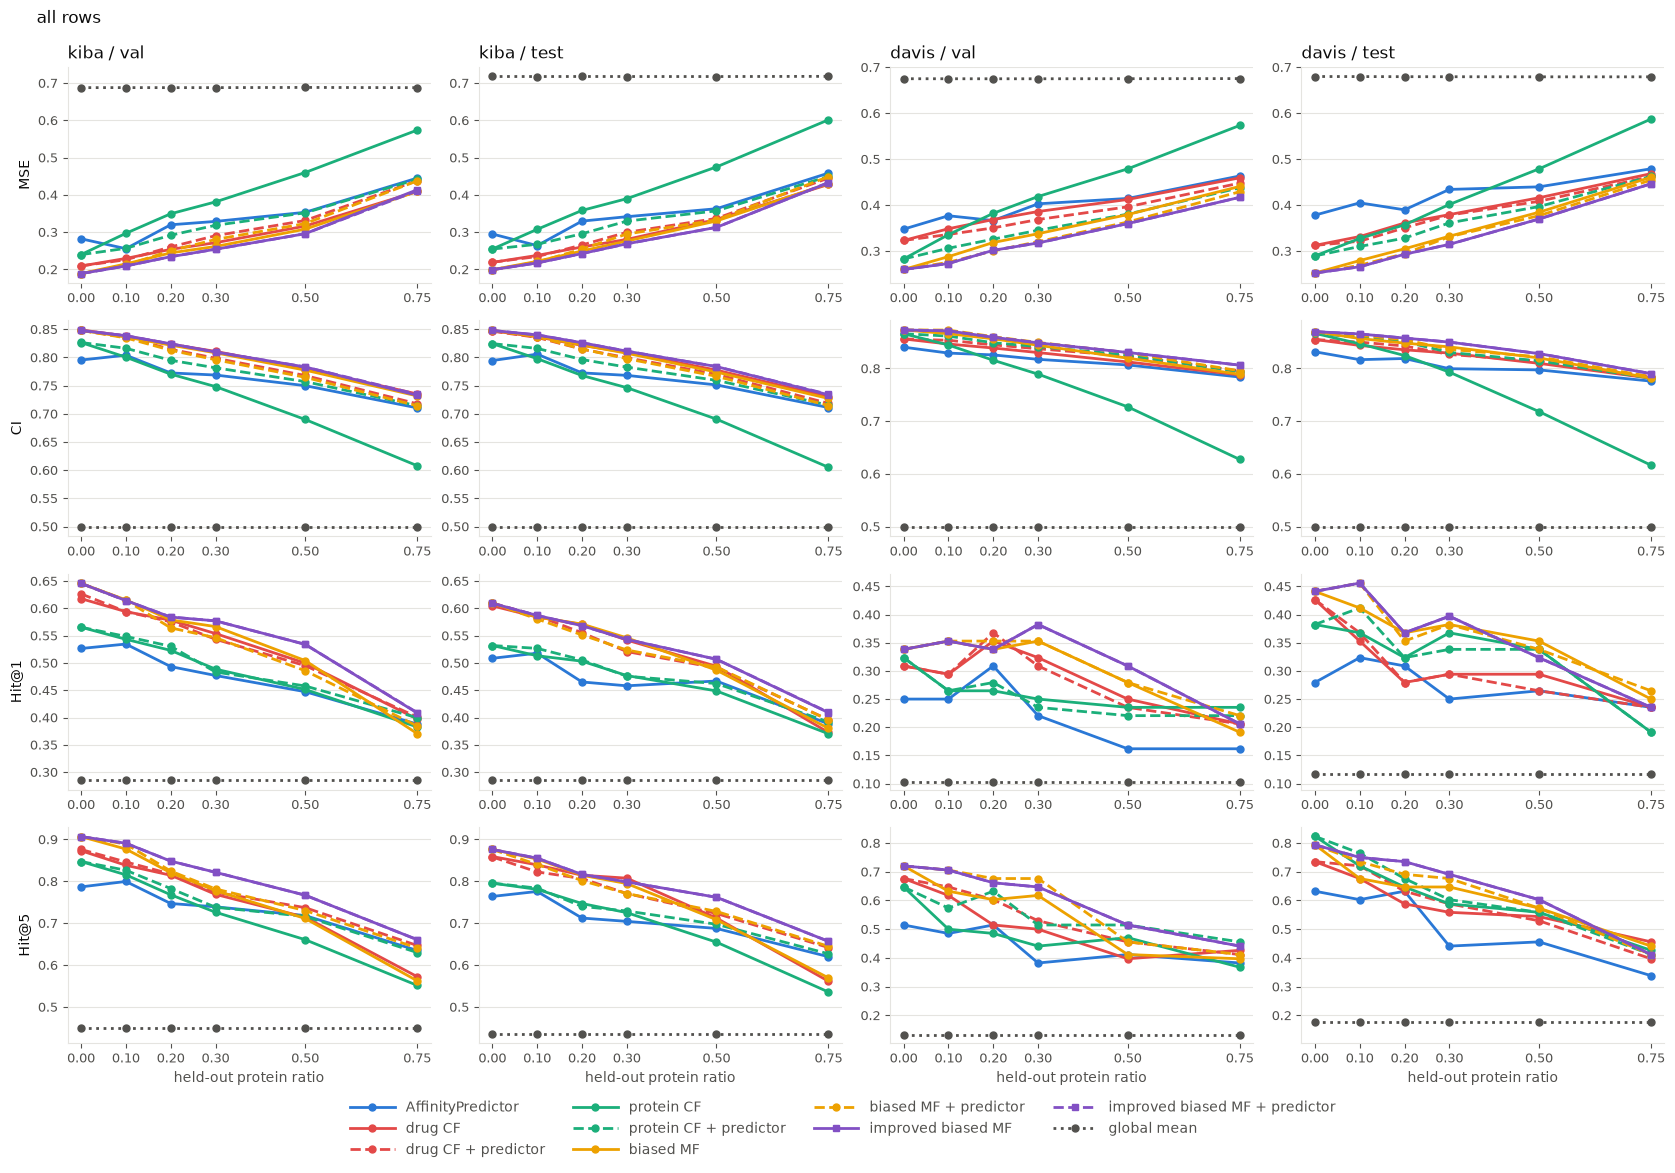

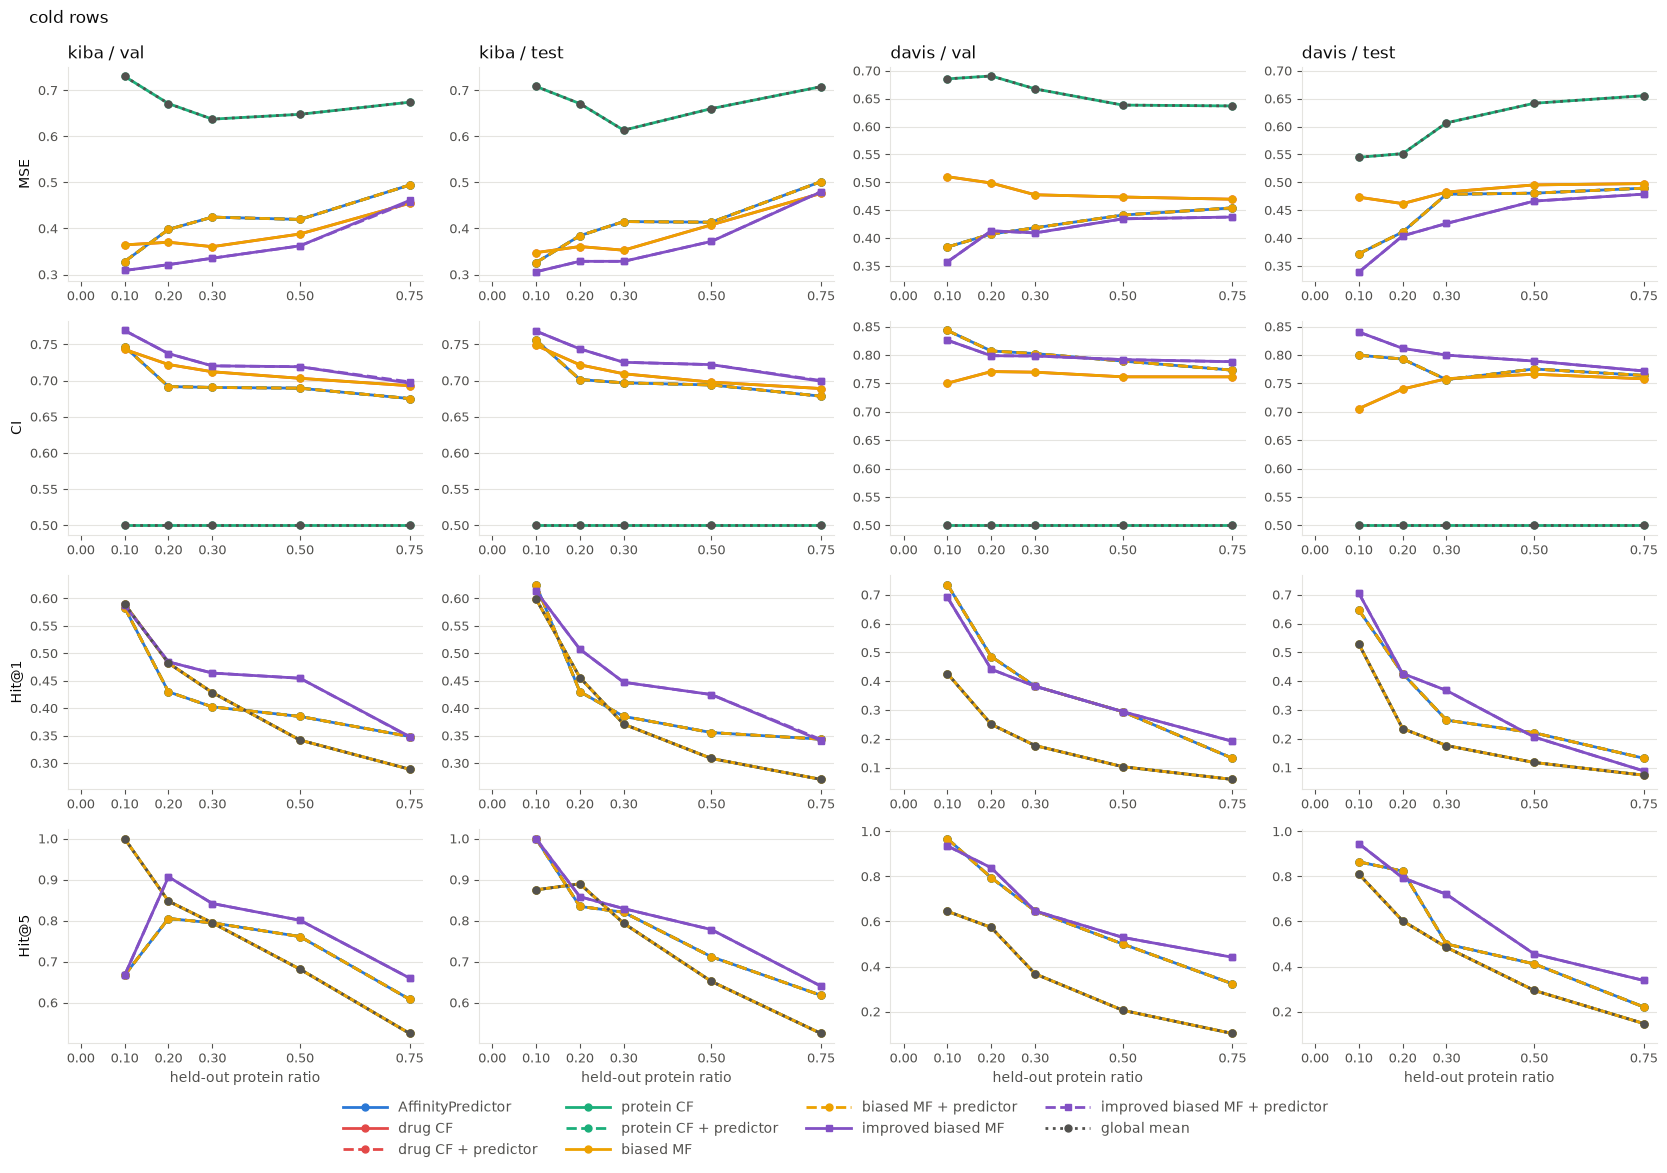

figures written to C:\Users\iamgr\Desktop\SC4020-Lab2\open_task\figures


In [11]:
CURVE_METRICS = ("MSE", "CI", "Hit@1", "Hit@5")
CURVE_GROUPS = ("all rows", "cold rows")

SERIES = {
    MODEL_NAME: (PREDICTOR_COLOR, "-", "o"),
    "drug CF": (DRUG_CF_COLOR, "-", "o"),
    "drug CF + predictor": (DRUG_CF_COLOR, "--", "o"),
    "protein CF": (PROTEIN_CF_COLOR, "-", "o"),
    "protein CF + predictor": (PROTEIN_CF_COLOR, "--", "o"),
    "biased MF": (BIASED_MF_COLOR, "-", "o"),
    "biased MF + predictor": (BIASED_MF_COLOR, "--", "o"),
    "improved biased MF": (IMPROVED_MF_COLOR, "-", "s"),
    "improved biased MF + predictor": (IMPROVED_MF_COLOR, "--", "s"),
    "global mean": (MUTED_COLOR, ":", "o"),
}

measured = pd.DataFrame(measurements)

def draw_curves(panel, dataset, split, group, metric, series=None):
    """One metric against the holdout ratio, every model as its own line."""
    for model, (colour, style, marker) in (SERIES if series is None else series).items():
        curve = measured[
            (measured["dataset"] == dataset)
            & (measured["split"] == split)
            & (measured["group"] == group)
            & (measured["model"] == model)
        ].sort_values("holdout")
        panel.plot(
            curve["holdout"], curve[metric], label=model,
            color=colour, linestyle=style, linewidth=2, marker=marker, markersize=5)

    panel.set_xticks(HOLDOUTS)
    panel.set_xlim(min(HOLDOUTS) - 0.03, max(HOLDOUTS) + 0.03)
    panel.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    panel.set_axisbelow(True)
    panel.spines["top"].set_visible(False)
    panel.spines["right"].set_visible(False)
    panel.spines["left"].set_color(GRID_COLOR)
    panel.spines["bottom"].set_color(GRID_COLOR)
    panel.tick_params(colors=MUTED_COLOR, labelsize=9)

def add_legend(figure, panel, anchor):
    handles, labels = panel.get_legend_handles_labels()
    figure.legend(
        handles, labels, loc="lower center", ncol=4, frameon=False,
        labelcolor=MUTED_COLOR, handlelength=3.2, bbox_to_anchor=anchor)

GRID_COLUMNS = [(dataset, split) for dataset in DATASETS for split in SPLITS]

def share_split_scales(panels):
    """One dataset's columns share a y scale per row; the two datasets never do.

    pKd and the KIBA score are different quantities, and DAVIS CI is not comparable to KIBA
    CI either, so a scale shared across datasets would imply a comparison that is not there.
    """
    for row in panels:
        for start in range(0, len(row), len(SPLITS)):
            pair = row[start:start + len(SPLITS)]
            limits = [panel.get_ylim() for panel in pair]
            for panel in pair:
                panel.set_ylim(min(low for low, _ in limits), max(high for _, high in limits))

def draw_focus_grid(series, group, name, metrics=("MSE", "CI", "Hit@1", "Hit@5"), title=None):
    """A dataset-by-split grid of metric rows for one short series list, saved as one file.

    Columns are every dataset crossed with every split, so a split sits beside its own
    replicate. One dataset's two columns share a y scale per row; the two datasets never do,
    because pKd and the KIBA score are different quantities and DAVIS CI is not comparable to
    KIBA CI either.
    """
    figure, panels = plt.subplots(
        len(metrics), len(GRID_COLUMNS),
        figsize=(4.2 * len(GRID_COLUMNS), 2.6 * len(metrics)), squeeze=False)

    for column, (dataset, split) in enumerate(GRID_COLUMNS):
        for row, metric in enumerate(metrics):
            panel = panels[row][column]
            draw_curves(panel, dataset, split, group, metric, series)

            if row == 0:
                panel.set_title(f"{dataset} / {split}", color=TEXT_COLOR, loc="left")
            if row == len(metrics) - 1:
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
            if column == 0:
                panel.set_ylabel(metric, color=TEXT_COLOR)

    share_split_scales(panels)
    add_legend(figure, panels[0][0], (0.5, -0.01))
    figure.suptitle(f"{title or name} / {group}", color=TEXT_COLOR, x=0.02, ha="left")
    figure.tight_layout(rect=(0, 0.03, 1, 0.99))

    figure.savefig(
        FOCUS_PATTERN.format(name=name, split="val_test", group=group.replace(" ", "_")),
        dpi=150, bbox_inches="tight")
    plt.show()

for group in CURVE_GROUPS:
    figure, panels = plt.subplots(
        len(CURVE_METRICS), len(GRID_COLUMNS),
        figsize=(4.2 * len(GRID_COLUMNS), 2.9 * len(CURVE_METRICS)), squeeze=False)

    for column, (dataset, split) in enumerate(GRID_COLUMNS):
        for row, metric in enumerate(CURVE_METRICS):
            panel = panels[row][column]
            draw_curves(panel, dataset, split, group, metric)

            if row == 0:
                panel.set_title(f"{dataset} / {split}", color=TEXT_COLOR, loc="left")
            if row == len(CURVE_METRICS) - 1:
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
            if column == 0:
                panel.set_ylabel(metric, color=TEXT_COLOR)

    share_split_scales(panels)
    add_legend(figure, panels[0][0], (0.5, -0.02))
    figure.suptitle(group, color=TEXT_COLOR, x=0.02, ha="left")
    figure.tight_layout(rect=(0, 0.04, 1, 0.99))

    figure.savefig(
        CURVE_PATTERN.format(split="val_test", group=group.replace(" ", "_")),
        dpi=150, bbox_inches="tight")
    plt.show()

for split in SPLITS:
    for group in CURVE_GROUPS:
        for dataset in DATASETS:
            for metric in CURVE_METRICS:
                figure, panel = plt.subplots(figsize=(6.4, 4.0))
                draw_curves(panel, dataset, split, group, metric)

                panel.set_title(
                    f"{dataset} / {split} / {group}", color=TEXT_COLOR, loc="left")
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
                panel.set_ylabel(metric, color=TEXT_COLOR)
                add_legend(figure, panel, (0.5, -0.13))

                figure.savefig(
                    PANEL_PATTERN.format(
                        split=split, group=group.replace(" ", "_"), dataset=dataset,
                        metric=metric.lower().replace("@", "")),
                    dpi=150, bbox_inches="tight")
                plt.close(figure)

print("figures written to", FIGURE_DIR)

### Embeddings against Global Mean

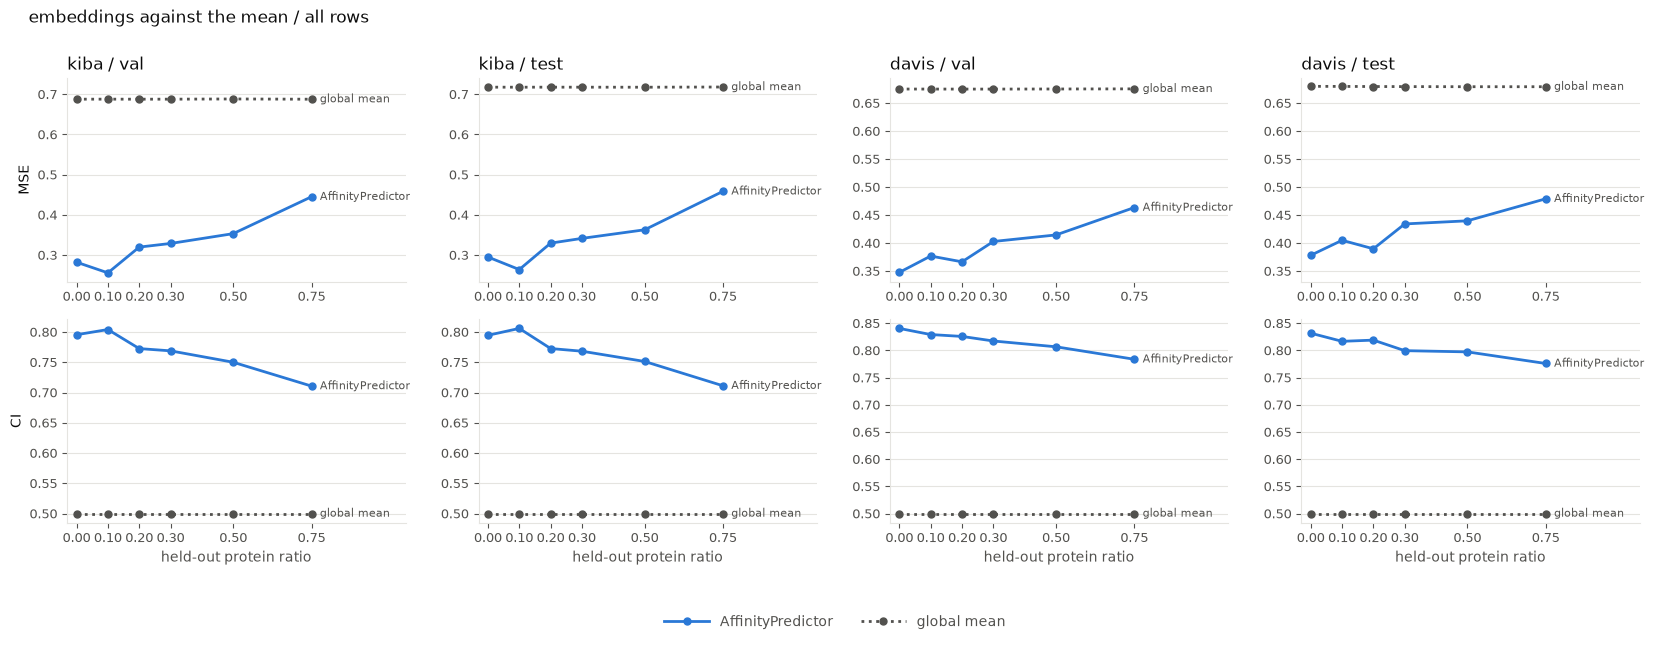

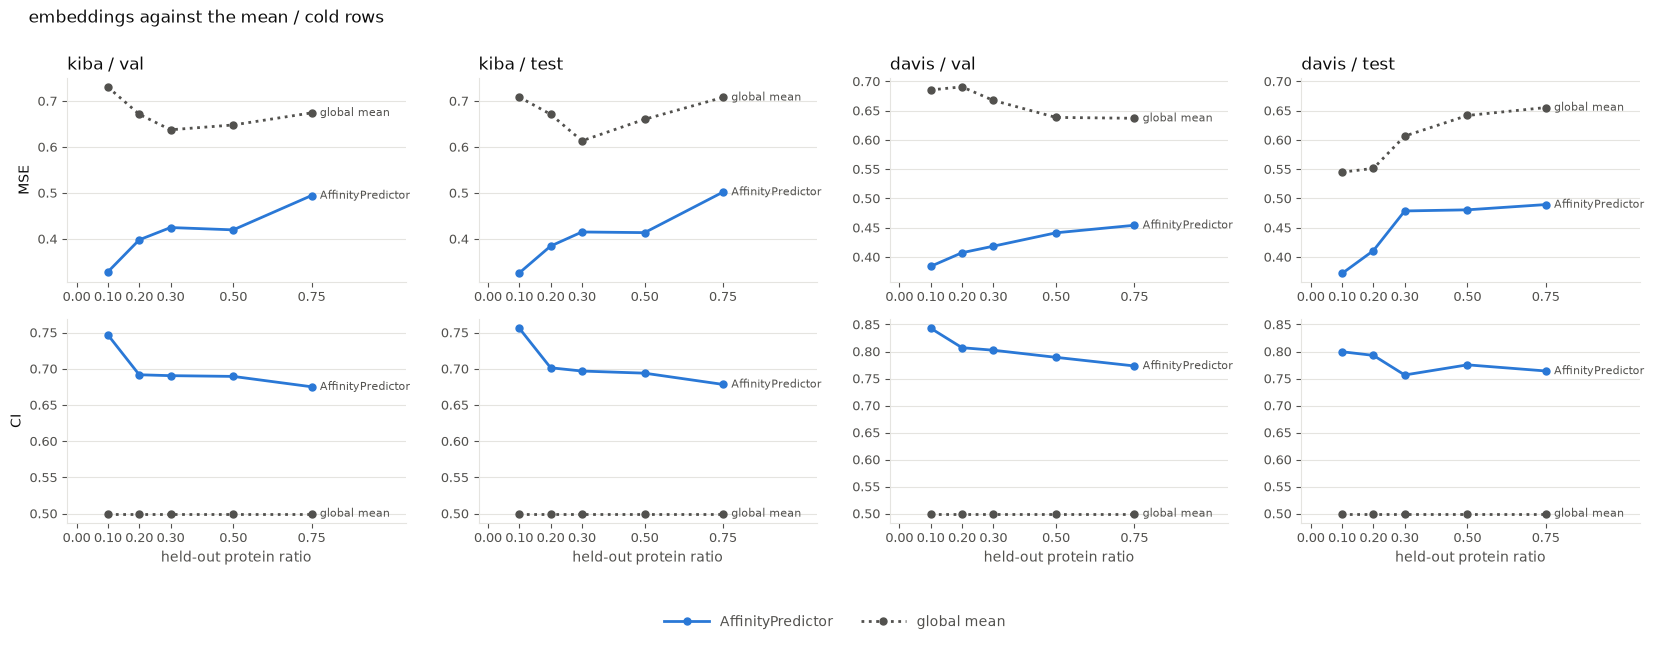

In [12]:
EMBEDDING_SERIES = {key: SERIES[key] for key in (MODEL_NAME, "global mean")}
EMBEDDING_METRICS = ("MSE", "CI")

def label_ends(panel, dataset, split, group, metric, series):
    """Direct labels, so a short series list is not told apart by colour alone."""
    for model, (colour, _, _marker) in series.items():
        curve = measured[
            (measured["dataset"] == dataset)
            & (measured["split"] == split)
            & (measured["group"] == group)
            & (measured["model"] == model)
        ].sort_values("holdout")
        panel.annotate(
            model, xy=(curve["holdout"].iloc[-1], curve[metric].iloc[-1]),
            xytext=(6, 0), textcoords="offset points",
            fontsize=8, color=MUTED_COLOR, va="center")

    panel.set_xlim(min(HOLDOUTS) - 0.03, max(HOLDOUTS) + 0.3)

for group in CURVE_GROUPS:
    figure, panels = plt.subplots(
        len(EMBEDDING_METRICS), len(GRID_COLUMNS),
        figsize=(4.2 * len(GRID_COLUMNS), 3.1 * len(EMBEDDING_METRICS)), squeeze=False)

    for column, (dataset, split) in enumerate(GRID_COLUMNS):
        for row, metric in enumerate(EMBEDDING_METRICS):
            panel = panels[row][column]
            draw_curves(panel, dataset, split, group, metric, EMBEDDING_SERIES)
            label_ends(panel, dataset, split, group, metric, EMBEDDING_SERIES)

            if row == 0:
                panel.set_title(f"{dataset} / {split}", color=TEXT_COLOR, loc="left")
            if row == len(EMBEDDING_METRICS) - 1:
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
            if column == 0:
                panel.set_ylabel(metric, color=TEXT_COLOR)

    share_split_scales(panels)
    add_legend(figure, panels[0][0], (0.5, -0.04))
    figure.suptitle(
        f"embeddings against the mean / {group}", color=TEXT_COLOR, x=0.02, ha="left")
    figure.tight_layout(rect=(0, 0.06, 1, 0.98))

    figure.savefig(
        FOCUS_PATTERN.format(
            name="embeddings", split="val_test", group=group.replace(" ", "_")),
        dpi=150, bbox_inches="tight")
    plt.show()

### AffinityPredictor vs Baseline CFs

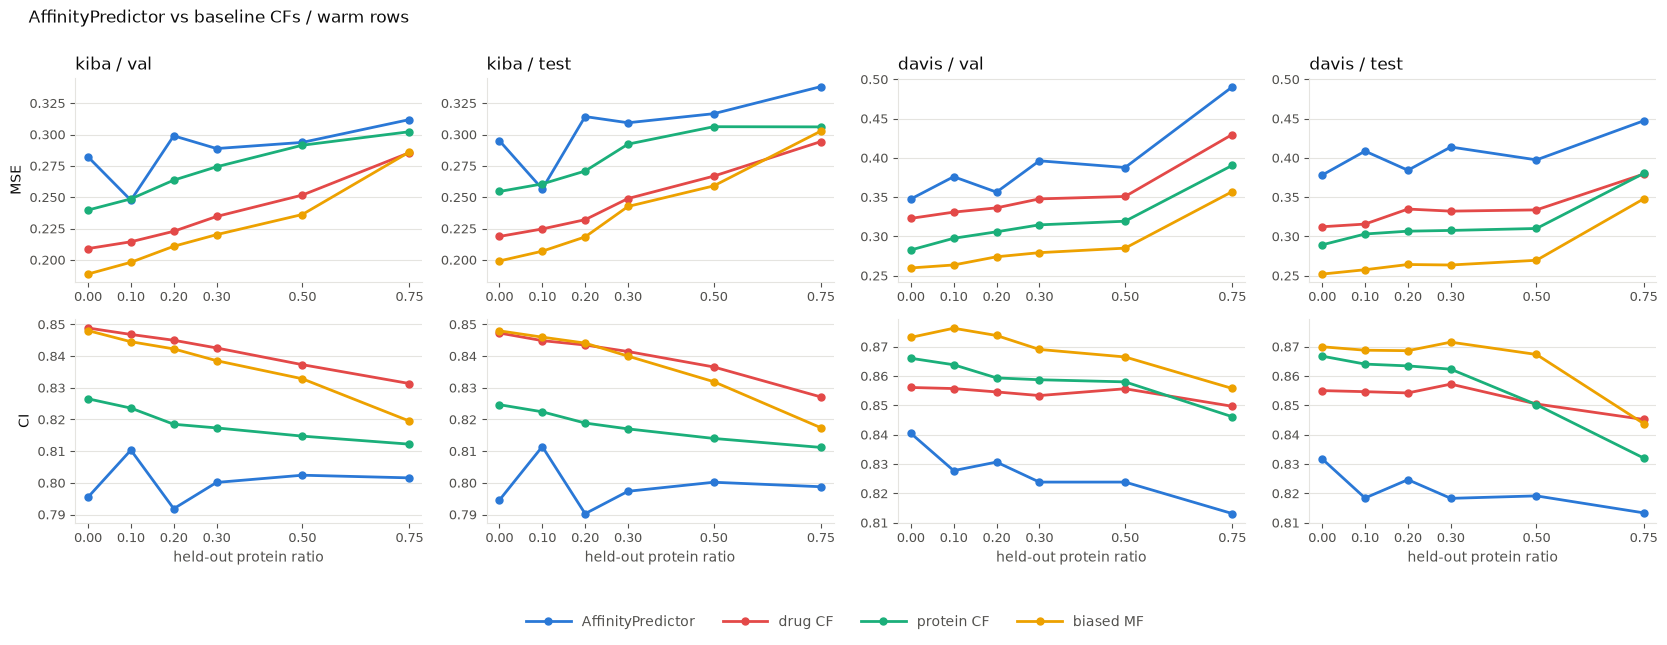

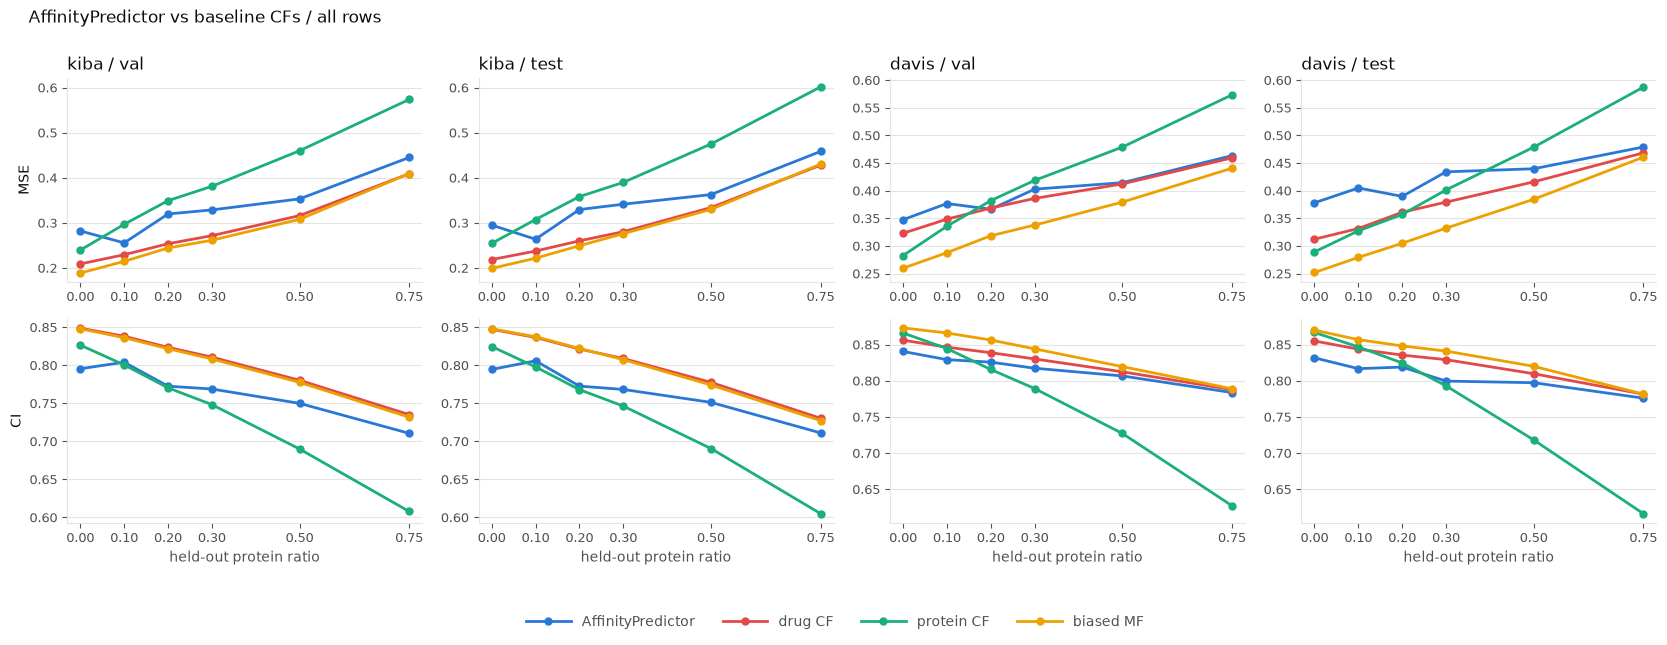

In [13]:
BASELINE_SERIES = {
    key: SERIES[key] for key in (MODEL_NAME, "drug CF", "protein CF", "biased MF")}
BASELINE_METRICS = ("MSE", "CI")
BASELINE_GROUPS = ("warm rows", "all rows")

for group in BASELINE_GROUPS:
    figure, panels = plt.subplots(
        len(BASELINE_METRICS), len(GRID_COLUMNS),
        figsize=(4.2 * len(GRID_COLUMNS), 3.1 * len(BASELINE_METRICS)), squeeze=False)

    for column, (dataset, split) in enumerate(GRID_COLUMNS):
        for row, metric in enumerate(BASELINE_METRICS):
            panel = panels[row][column]
            draw_curves(panel, dataset, split, group, metric, BASELINE_SERIES)

            if row == 0:
                panel.set_title(f"{dataset} / {split}", color=TEXT_COLOR, loc="left")
            if row == len(BASELINE_METRICS) - 1:
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
            if column == 0:
                panel.set_ylabel(metric, color=TEXT_COLOR)

    share_split_scales(panels)
    add_legend(figure, panels[0][0], (0.5, -0.04))
    figure.suptitle(
        f"AffinityPredictor vs baseline CFs / {group}", color=TEXT_COLOR, x=0.02, ha="left")
    figure.tight_layout(rect=(0, 0.06, 1, 0.98))

    figure.savefig(
        FOCUS_PATTERN.format(
            name="baseline_cfs", split="val_test", group=group.replace(" ", "_")),
        dpi=150, bbox_inches="tight")
    plt.show()

### Predictor Fallback vs Mean Fallback

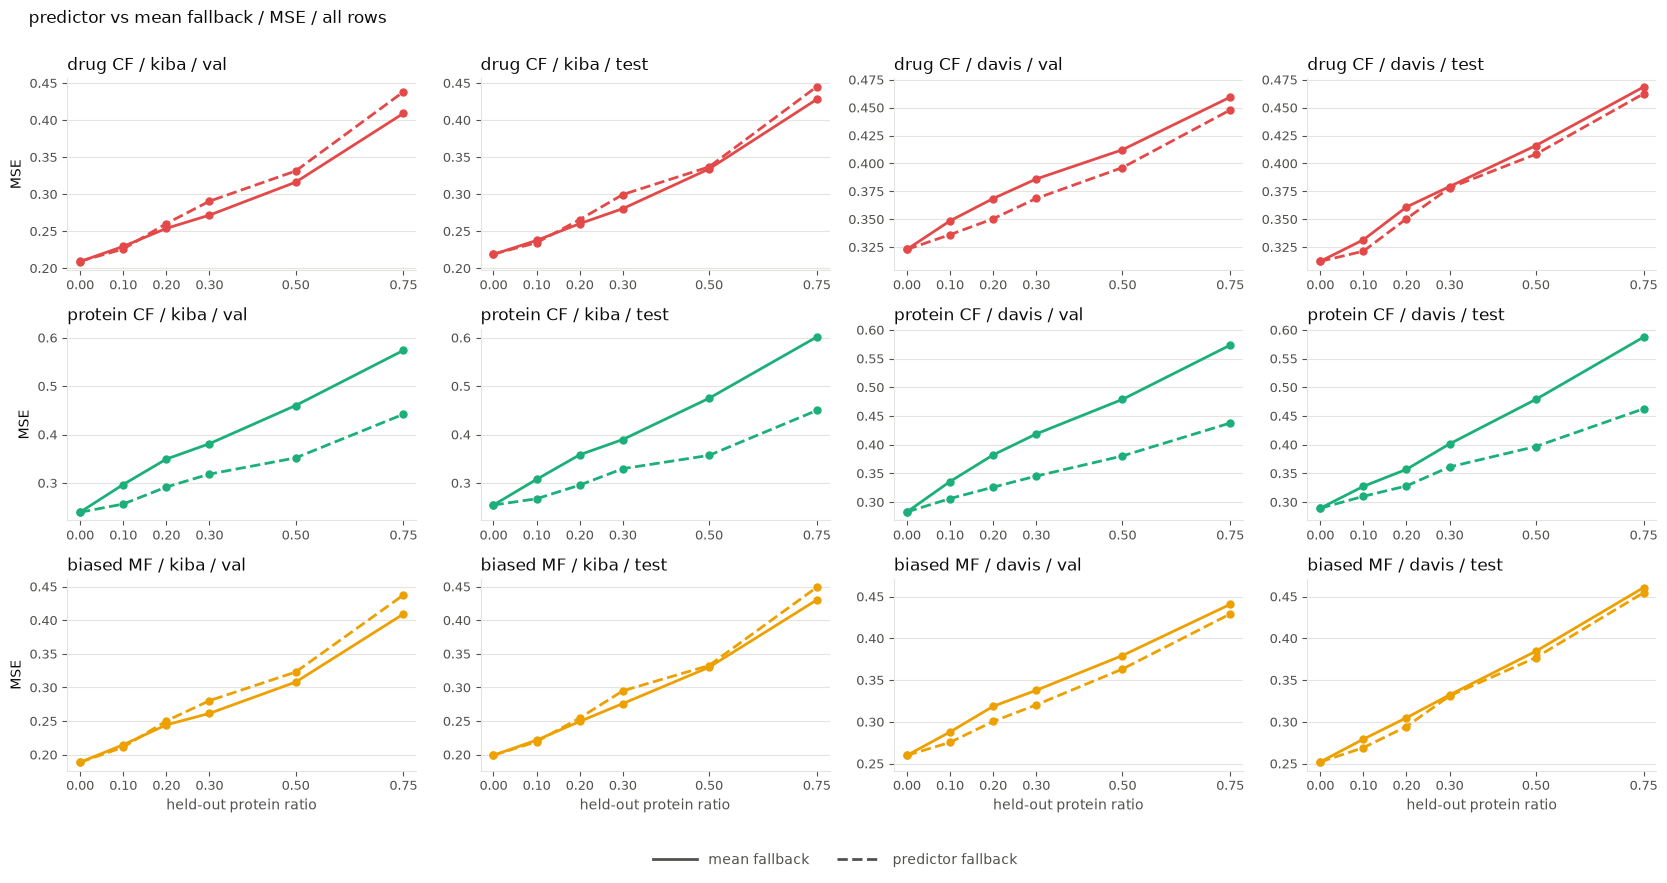

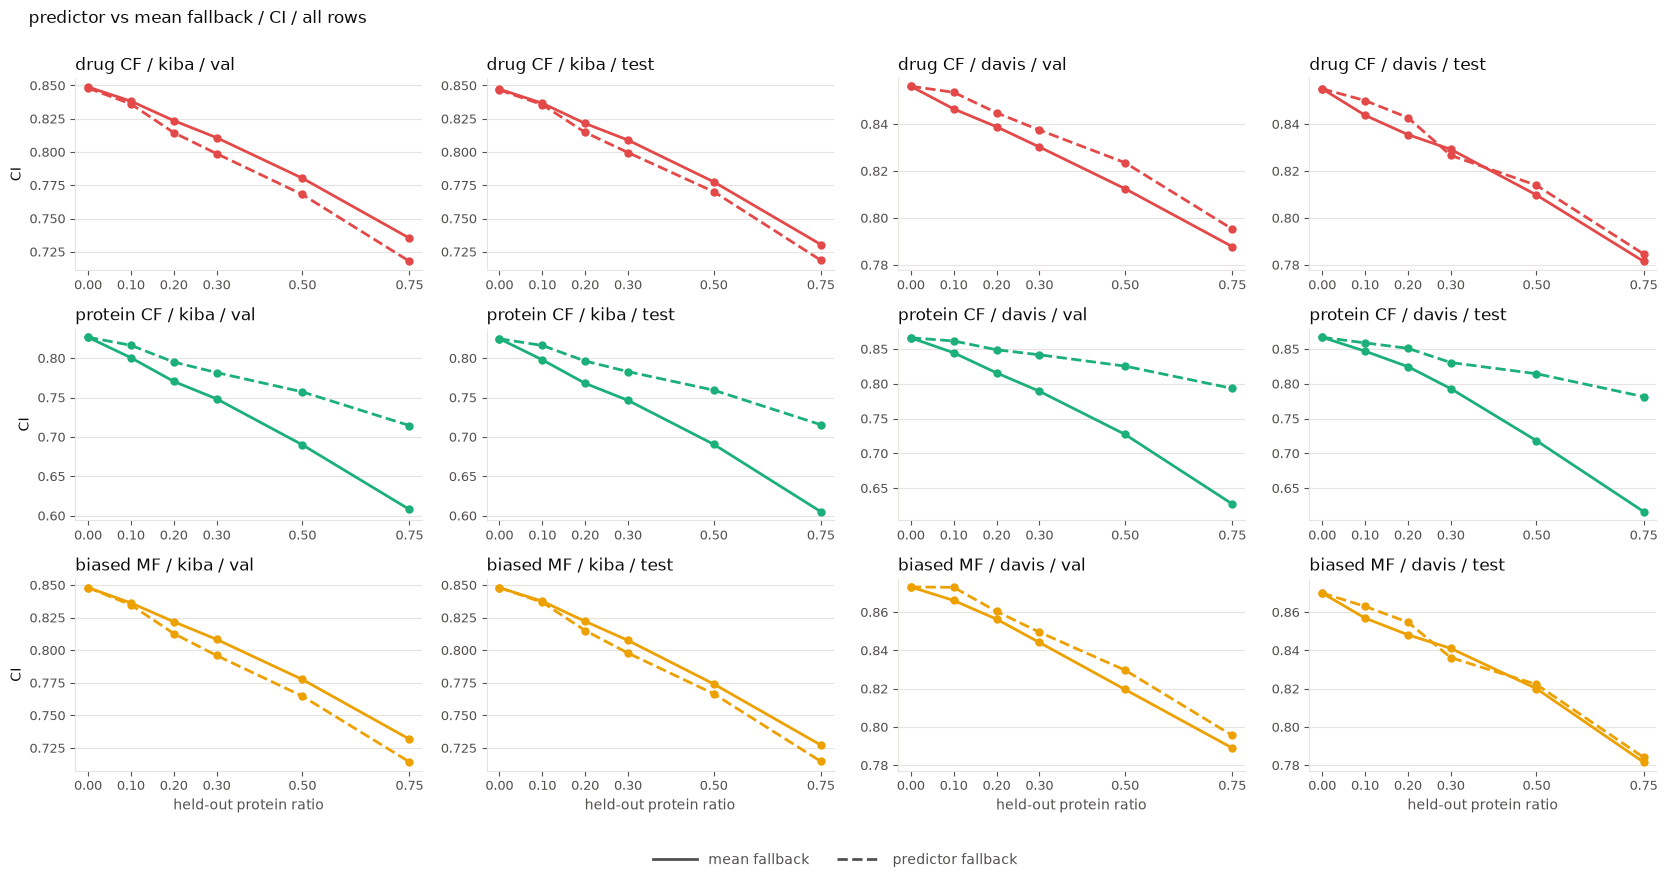

In [14]:
from matplotlib.lines import Line2D

FALLBACK_BASES = ("drug CF", "protein CF", "biased MF")
FALLBACK_METRICS = ("MSE", "CI")
FALLBACK_GROUP = "all rows"

for metric in FALLBACK_METRICS:
    figure, panels = plt.subplots(
        len(FALLBACK_BASES), len(GRID_COLUMNS),
        figsize=(4.2 * len(GRID_COLUMNS), 2.9 * len(FALLBACK_BASES)), squeeze=False)

    for row, base in enumerate(FALLBACK_BASES):
        pair = {name: SERIES[name] for name in (base, f"{base} + predictor")}

        for column, (dataset, split) in enumerate(GRID_COLUMNS):
            panel = panels[row][column]
            draw_curves(panel, dataset, split, FALLBACK_GROUP, metric, pair)

            panel.set_title(f"{base} / {dataset} / {split}", color=TEXT_COLOR, loc="left")
            if row == len(FALLBACK_BASES) - 1:
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
            if column == 0:
                panel.set_ylabel(metric, color=TEXT_COLOR)

    share_split_scales(panels)

    handles = [
        Line2D([], [], color=MUTED_COLOR, linestyle="-", linewidth=2),
        Line2D([], [], color=MUTED_COLOR, linestyle="--", linewidth=2),
    ]
    figure.legend(
        handles, ["mean fallback", "predictor fallback"], loc="lower center", ncol=2,
        frameon=False, labelcolor=MUTED_COLOR, handlelength=3.2,
        bbox_to_anchor=(0.5, -0.02))
    figure.suptitle(
        f"predictor vs mean fallback / {metric} / {FALLBACK_GROUP}",
        color=TEXT_COLOR, x=0.02, ha="left")
    figure.tight_layout(rect=(0, 0.04, 1, 0.98))

    figure.savefig(
        FOCUS_PATTERN.format(
            name=f"fallback_{metric.lower()}", split="val_test",
            group=FALLBACK_GROUP.replace(" ", "_")),
        dpi=150, bbox_inches="tight")
    plt.show()

### Recommendation Ranking as Proteins Are Held Out

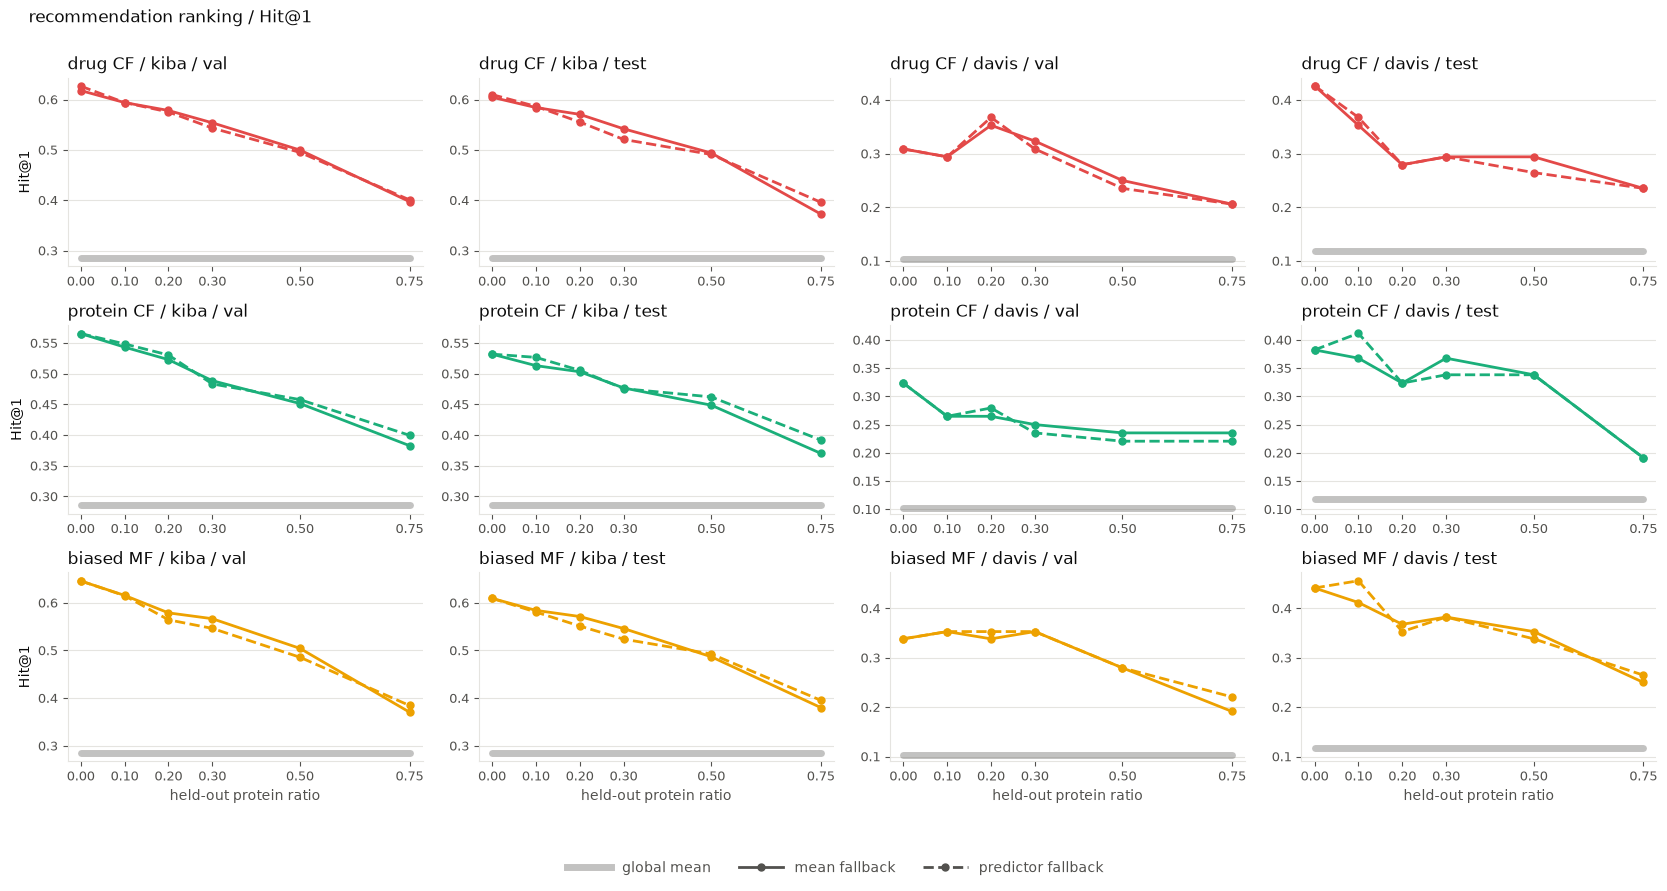

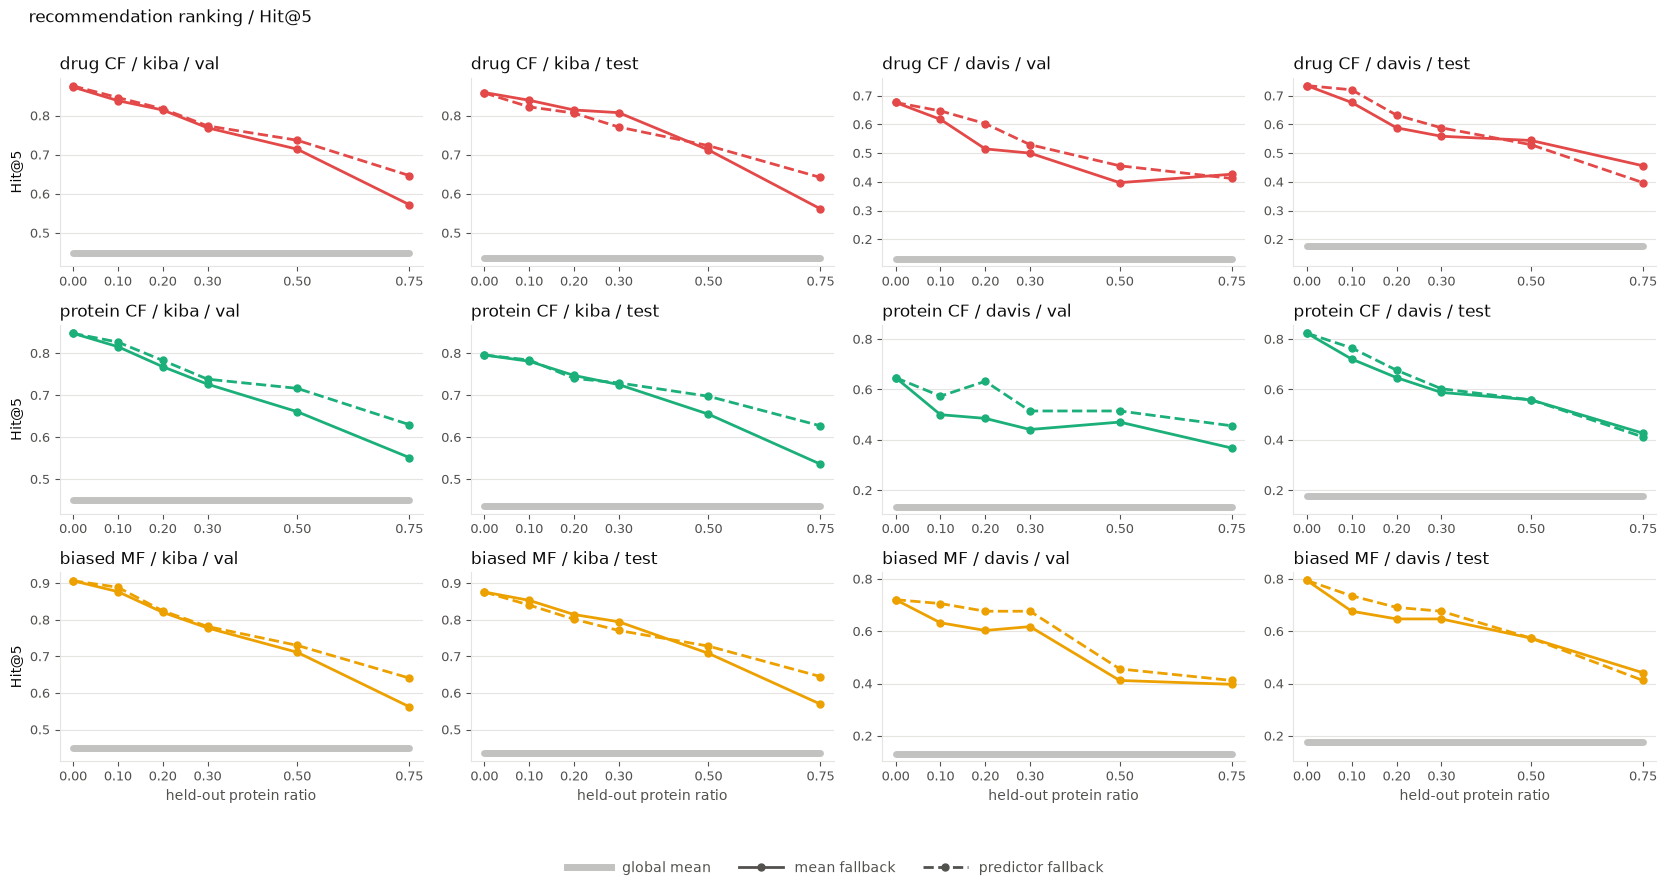

In [15]:
from matplotlib.lines import Line2D

RANKING_BASES = ("drug CF", "protein CF", "biased MF")
RANKING_METRICS = ("Hit@1", "Hit@5")
RANKING_GROUP = "all rows"

def draw_global_mean(panel, dataset, split, group, metric):
    """Drawn thick underneath: the score a model that cannot rank at all earns."""
    curve = measured[
        (measured["dataset"] == dataset)
        & (measured["split"] == split)
        & (measured["group"] == group)
        & (measured["model"] == "global mean")
    ].sort_values("holdout")
    panel.plot(
        curve["holdout"], curve[metric], label="global mean",
        color=MUTED_COLOR, linewidth=5, alpha=0.35, solid_capstyle="round", zorder=1)

def finish_ranking(figure, handles, labels, ncol, group, name, title):
    """Shared legend, title and file for the two ranking figures."""
    figure.legend(
        handles, labels, loc="lower center", ncol=ncol, frameon=False,
        labelcolor=MUTED_COLOR, handlelength=3.2, bbox_to_anchor=(0.5, -0.03))
    figure.suptitle(title, color=TEXT_COLOR, x=0.02, ha="left")
    figure.tight_layout(rect=(0, 0.05, 1, 0.98))

    figure.savefig(
        FOCUS_PATTERN.format(name=name, split="val_test", group=group.replace(" ", "_")),
        dpi=150, bbox_inches="tight")
    plt.show()

PAIR_HANDLES = [
    Line2D([], [], color=MUTED_COLOR, linewidth=5, alpha=0.35),
    Line2D([], [], color=MUTED_COLOR, linestyle="-", linewidth=2, marker="o", markersize=5),
    Line2D([], [], color=MUTED_COLOR, linestyle="--", linewidth=2, marker="o", markersize=5),
]
PAIR_LABELS = ["global mean", "mean fallback", "predictor fallback"]

for metric in RANKING_METRICS:
    figure, panels = plt.subplots(
        len(RANKING_BASES), len(GRID_COLUMNS),
        figsize=(4.2 * len(GRID_COLUMNS), 2.9 * len(RANKING_BASES)), squeeze=False)

    for row, base in enumerate(RANKING_BASES):
        pair = {key: SERIES[key] for key in (base, f"{base} + predictor")}

        for column, (dataset, split) in enumerate(GRID_COLUMNS):
            panel = panels[row][column]
            draw_global_mean(panel, dataset, split, RANKING_GROUP, metric)
            draw_curves(panel, dataset, split, RANKING_GROUP, metric, pair)

            panel.set_title(f"{base} / {dataset} / {split}", color=TEXT_COLOR, loc="left")
            if row == len(RANKING_BASES) - 1:
                panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
            if column == 0:
                panel.set_ylabel(metric, color=TEXT_COLOR)

    share_split_scales(panels)
    finish_ranking(
        figure, PAIR_HANDLES, PAIR_LABELS, 3, RANKING_GROUP,
        f"recommendation_ranking_{metric.lower().replace('@', '')}",
        f"recommendation ranking / {metric}")

### Ranking Degrades to the Global Mean on Cold Rows

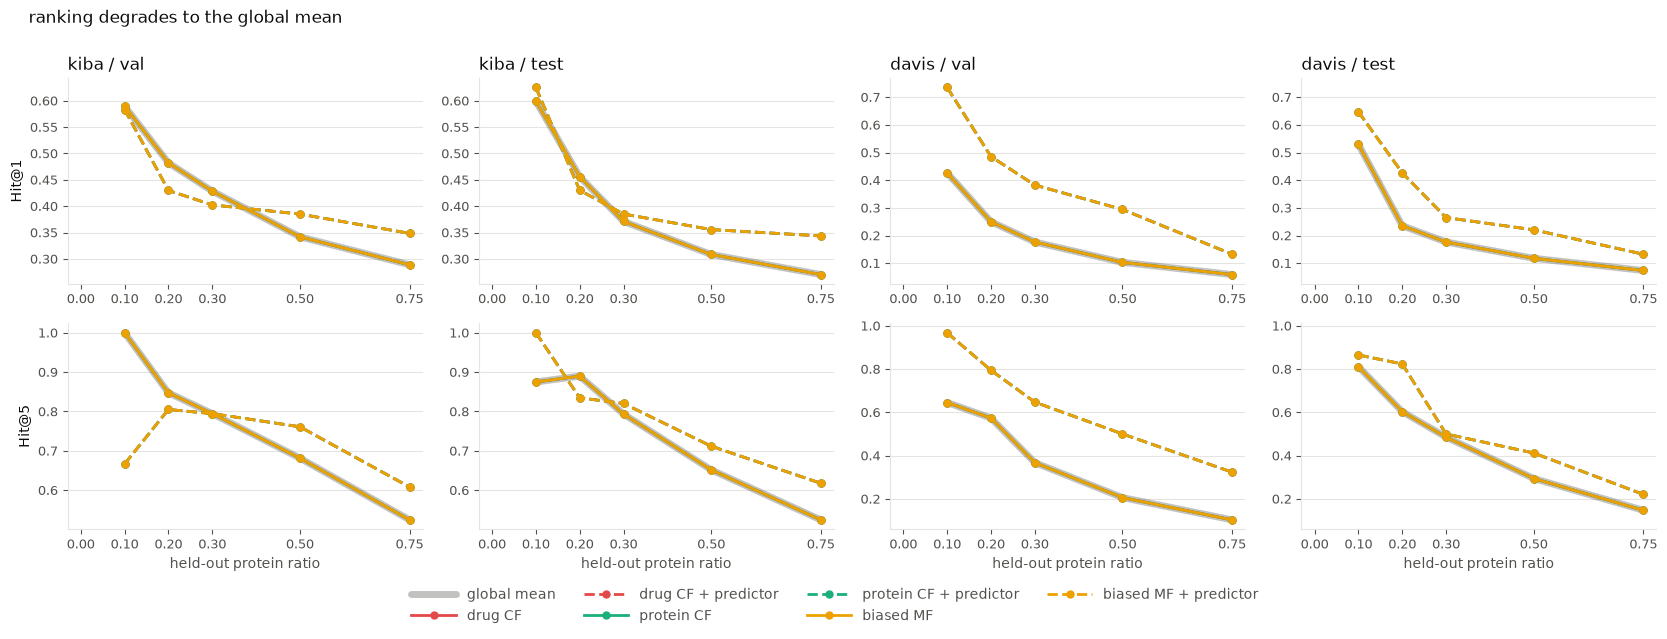

In [16]:
COLD_SERIES = {
    key: SERIES[key]
    for base in RANKING_BASES
    for key in (base, f"{base} + predictor")
}

figure, panels = plt.subplots(
    len(RANKING_METRICS), len(GRID_COLUMNS),
    figsize=(4.2 * len(GRID_COLUMNS), 3.1 * len(RANKING_METRICS)), squeeze=False)

for column, (dataset, split) in enumerate(GRID_COLUMNS):
    for row, metric in enumerate(RANKING_METRICS):
        panel = panels[row][column]
        draw_global_mean(panel, dataset, split, "cold rows", metric)
        draw_curves(panel, dataset, split, "cold rows", metric, COLD_SERIES)

        if row == 0:
            panel.set_title(f"{dataset} / {split}", color=TEXT_COLOR, loc="left")
        if row == len(RANKING_METRICS) - 1:
            panel.set_xlabel("held-out protein ratio", color=MUTED_COLOR)
        if column == 0:
            panel.set_ylabel(metric, color=TEXT_COLOR)

share_split_scales(panels)
handles, labels = panels[0][0].get_legend_handles_labels()
finish_ranking(
    figure, handles, labels, 4, "cold rows", "ranking_degradation",
    "ranking degrades to the global mean")

### Improved Biased MF vs Biased MF

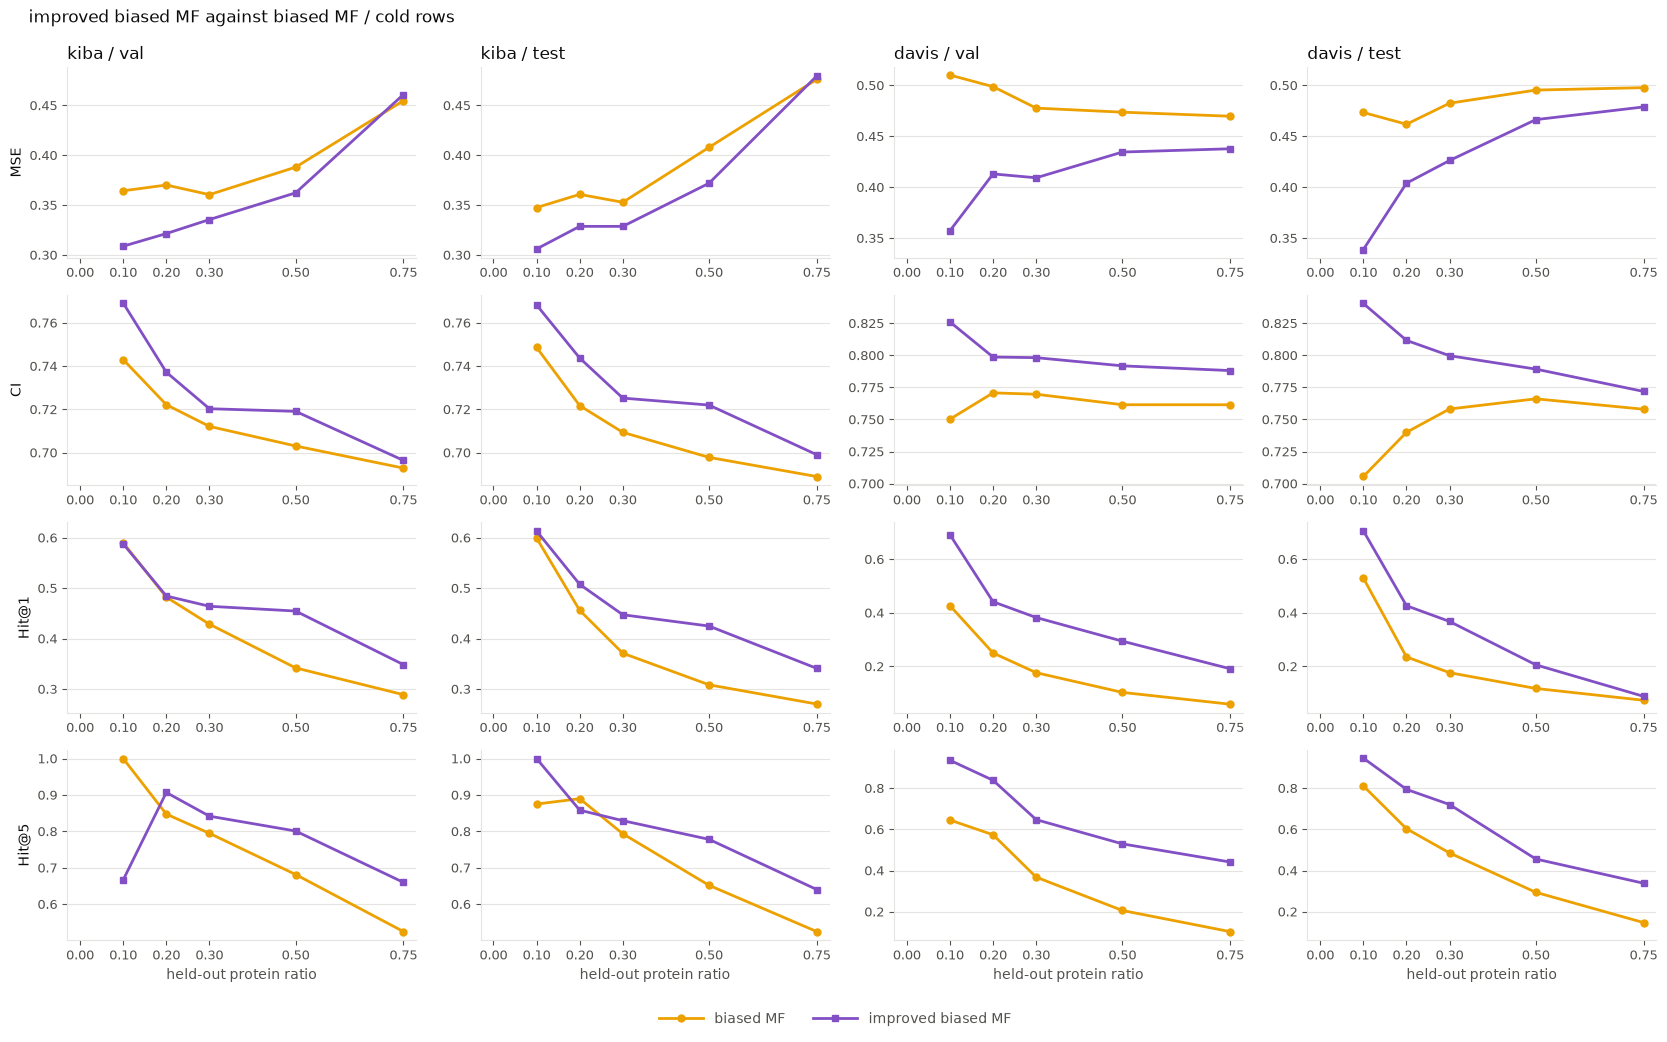

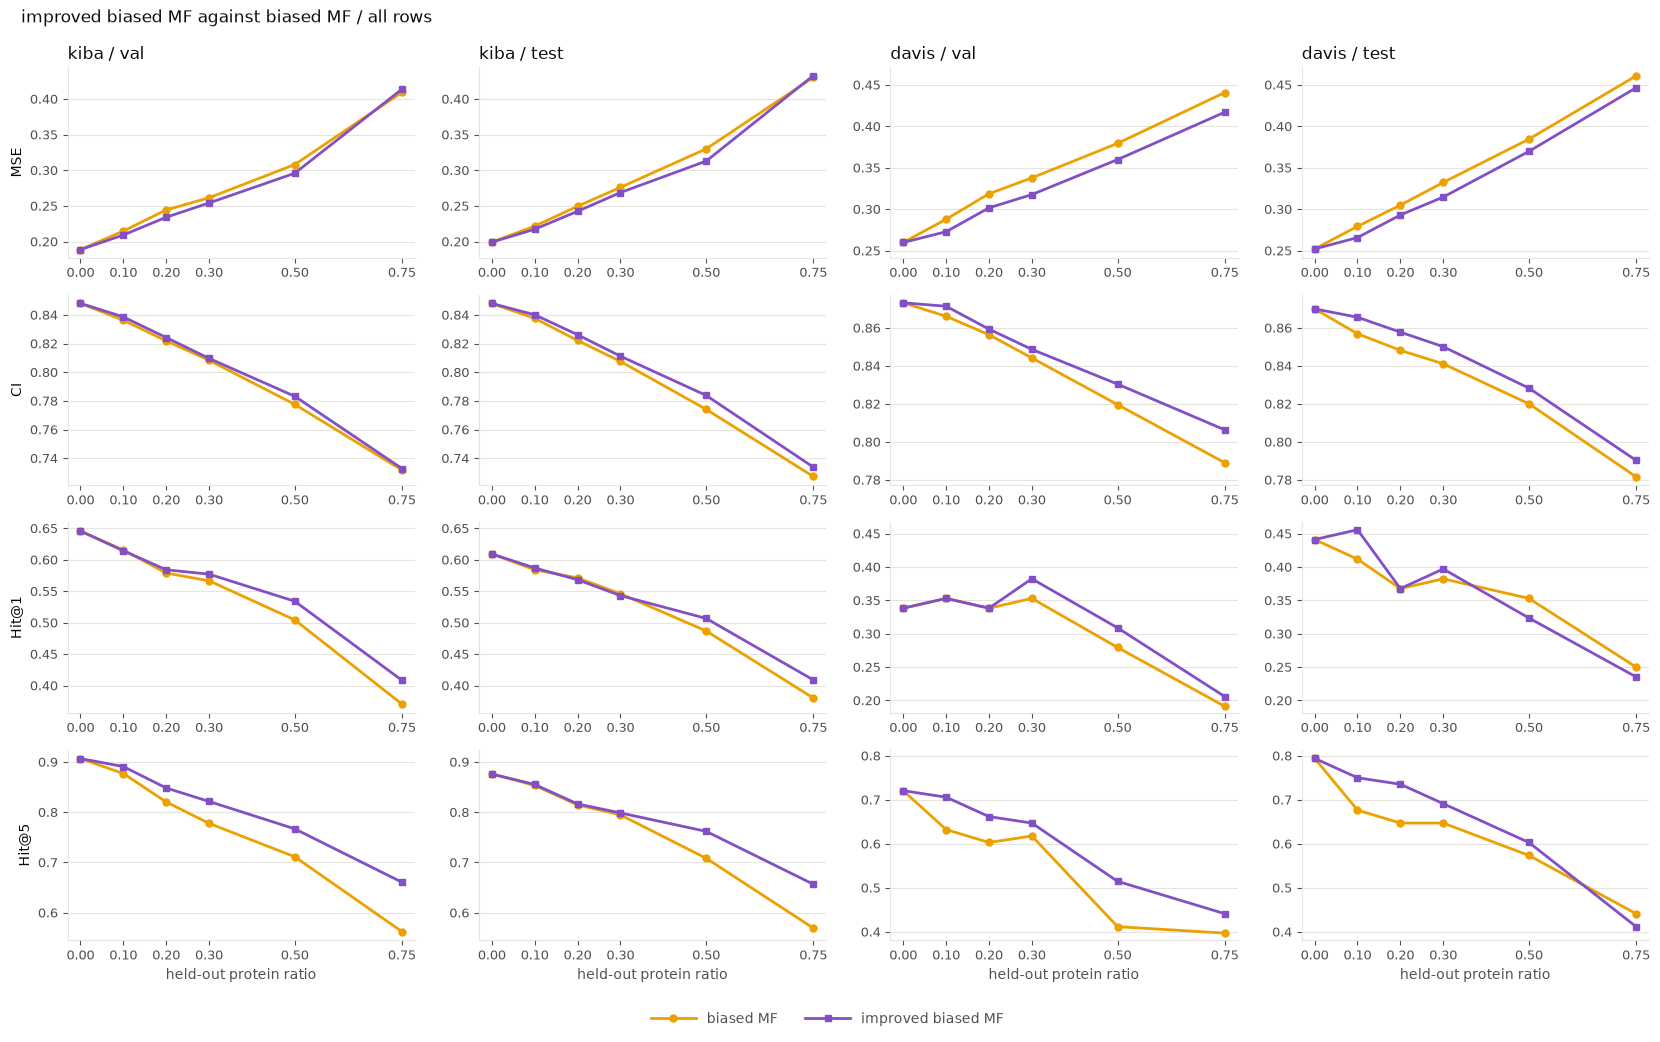

In [17]:
IMPROVED_SERIES = {key: SERIES[key] for key in ("biased MF", "improved biased MF")}
IMPROVED_GROUPS = ("cold rows", "all rows")

for group in IMPROVED_GROUPS:
    draw_focus_grid(
        IMPROVED_SERIES, group, "improved_biased_mf",
        title="improved biased MF against biased MF")

### Improved Biased MF vs the Collaborative Filtering Baselines

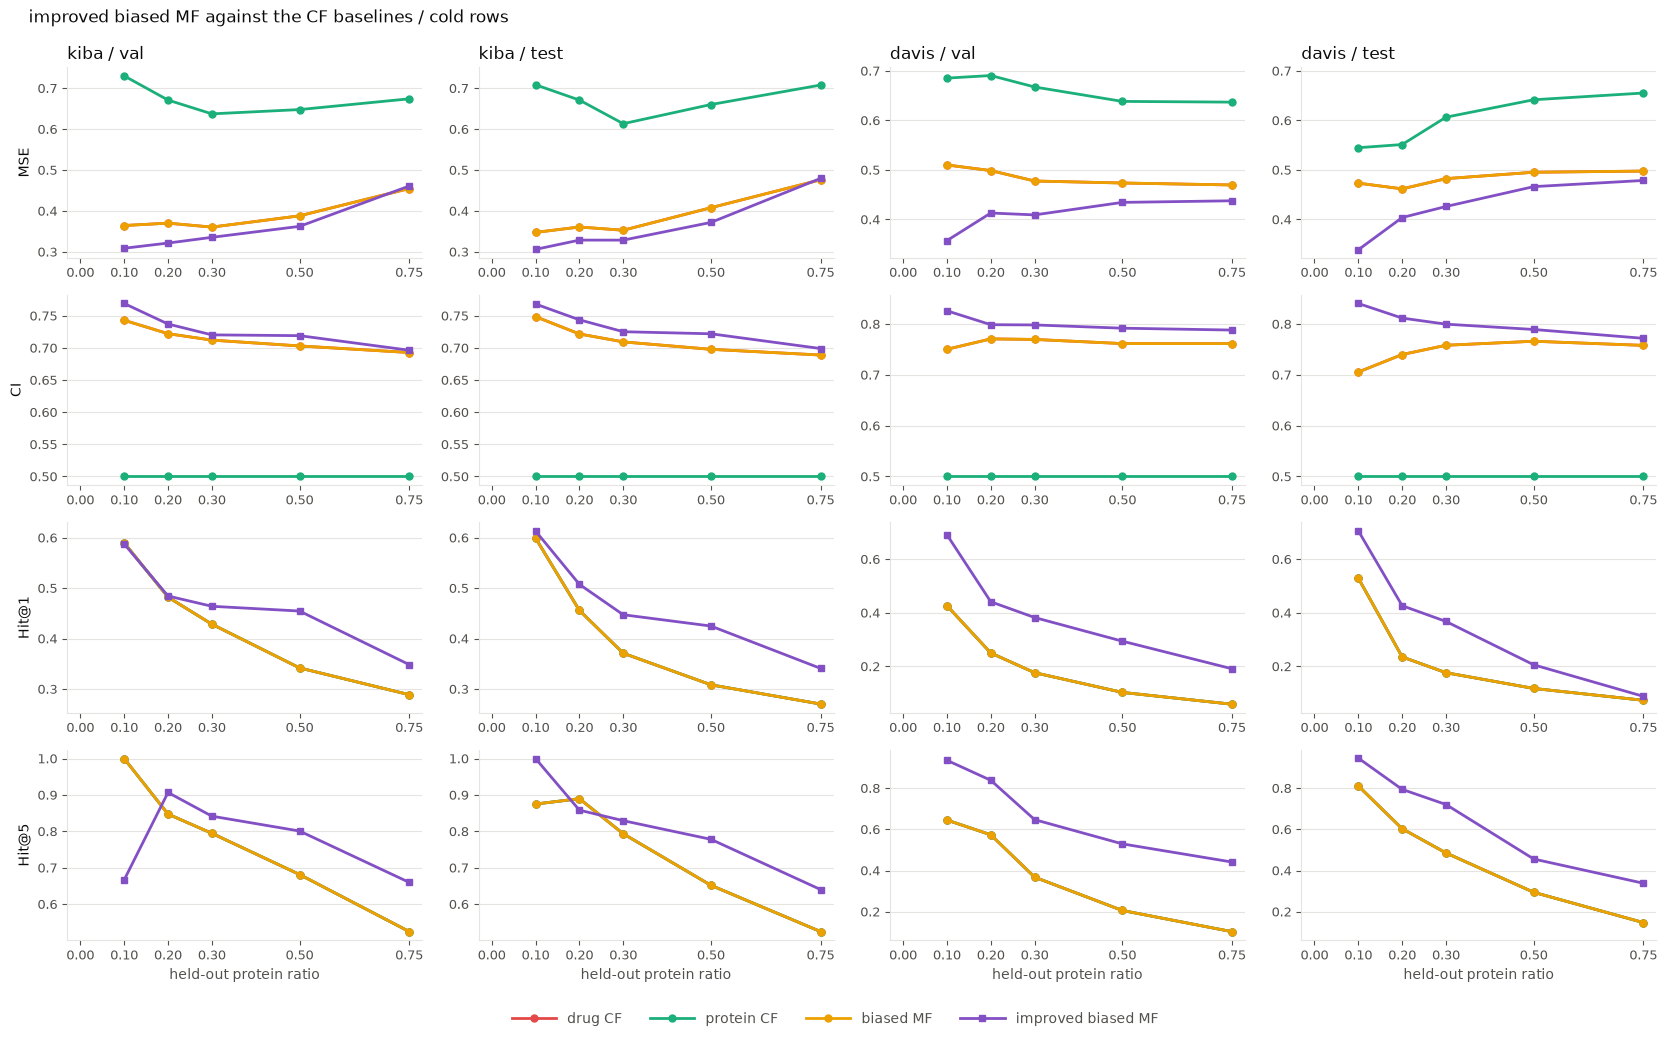

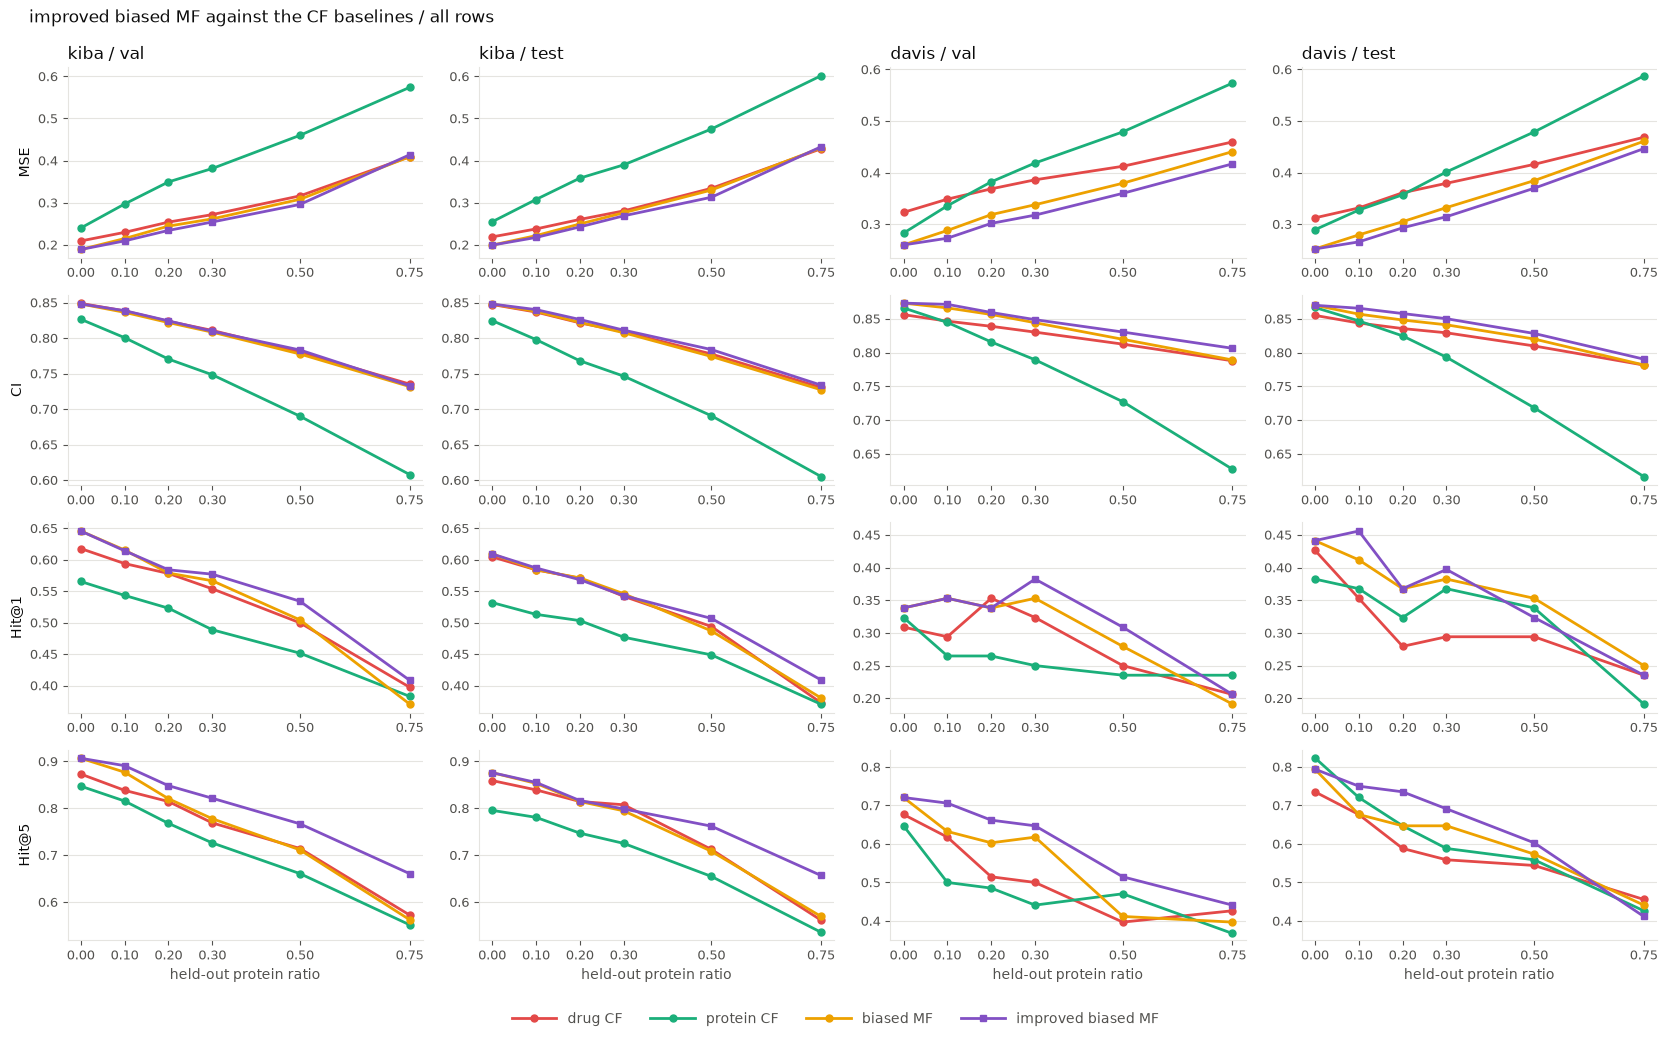

In [18]:
CF_SERIES = {
    key: SERIES[key]
    for key in ("drug CF", "protein CF", "biased MF", "improved biased MF")}

for group in IMPROVED_GROUPS:
    draw_focus_grid(
        CF_SERIES, group, "improved_vs_cf",
        title="improved biased MF against the CF baselines")